# Predicting Online Purchases — PRD v3.6
### DSA211 · Predictive classification · corrected sequential 1-SE selection

**Purpose:** Update the executed [v3.4 notebook](archive/versions/v3.4/online_shoppers_prd_v3_4.ipynb) to implement the [v3.6 requirements](PRD_v3.6.md) without rebuilding EDA, data, baselines or trees.

**Central change:** Each proposed modification inherits the current retained model. The rule selects the **simplest of the two models within one SE of their best CV ROC-AUC**. Stronger regularisation within inner-grid 1 SE is preferred. If an earlier accepted deletion makes a later experiment impossible, record the historical trial ID as **SKIPPED_INAPPLICABLE**, with no invented results.

**Provenance:** The historical v3.4 [experiment ledger](artifacts/prd_v3_4/all_attempts_ledger.csv) remains unchanged. V3.6 outputs go exclusively to `artifacts/prd_v3_6/`.

**Limitations:** Repeated exploration on the same training folds and the historically examined reserved set may bias reported performance upward. Neither the one-SE rule nor the illustrative business thresholds establishes statistical significance, causal impact or calibrated economic optimality.


## 0. Fixed analysis protocol — one-SE simplest model

**Selection at each sequential iteration:** Compare the incumbent and challenger using their five common training CV folds. Determine the best mean AUC and its SE (sample fold SD divided by sqrt(5)). Candidates with AUC at least `best AUC - best SE` are eligible; retain the **simpler eligible model**. If complexity ties, retain higher mean AUC (exact tie: incumbent).

**Complexity:** Number of fitted non-intercept nonzero coefficients for Logit (LASSO/Elastic Net sparsity counts), number of encoded input features for LDA and Naive Bayes. Report source-group counts separately. These are course-aligned project conventions, not a universal measure across classifier families.

**Inner regularisation:** On unchanged `C` grids for L4/L13/L14, choose the *smallest C* inside one SE of maximum three-fold mean inner ROC-AUC. For D4 shrinkage choose the strongest eligible shrinkage. Preprocessing, category pooling, thresholds, shrinkage and group selection are always fitted inside appropriate training folds.

**Experiment schedule:** All 41 historical IDs are considered, chronologically within each family, but some may now be incompatible and therefore skipped. Existing Gini and Entropy tree pruning already meets the one-SE rule and is unchanged. The highest mean five-fold AUC among six family finalists determines the final winner.


In [1]:
from pathlib import Path
import hashlib, json, warnings, platform, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, scipy, sklearn
from scipy import stats
from scipy.special import logsumexp
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.exceptions import ConvergenceWarning
import statsmodels.api as sm
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, log_loss, roc_curve, confusion_matrix

RUN_START=time.perf_counter()
SEED=42; TEST_FRAC=.20; K=5
TARGET='Revenue'
NUMERIC_ALL=['Administrative','Administrative_Duration','Informational','Informational_Duration',
 'ProductRelated','ProductRelated_Duration','BounceRates','ExitRates','PageValues','SpecialDay']
CAT=['Month','OperatingSystems','Browser','Region','TrafficType','VisitorType']
ACTIVITY=['Administrative','Administrative_Duration','Informational','Informational_Duration','ProductRelated','ProductRelated_Duration']
NUMERIC_SAFE=[x for x in NUMERIC_ALL if x!='PageValues']
ALL=NUMERIC_ALL+CAT+['Weekend']; SAFE=NUMERIC_SAFE+CAT+['Weekend']
EXPECTED=set(ALL+[TARGET])
root_candidates=[Path('data/uci_468.csv'),Path('../data/uci_468.csv')]
data_path=next((p for p in root_candidates if p.is_file()),None)
if data_path is None: raise FileNotFoundError('Run from repository root or a direct child directory; expected data/uci_468.csv')
ROOT=data_path.parent.parent if data_path.parent.name=='data' else data_path.parent.parent
ARTIFACTS=ROOT/'artifacts'; ARTIFACTS.mkdir(exist_ok=True)
WORK=ROOT/'work'; WORK.mkdir(exist_ok=True)
PROGRESS_LOG=WORK/'v3_6_progress.jsonl'; PROGRESS_LOG.write_text('')
def mark_progress(candidate,fold,event,**details):
    record={'candidate':candidate,'fold':fold,'event':event,'elapsed_seconds':round(time.perf_counter()-RUN_START,3),**details}
    with PROGRESS_LOG.open('a') as f: f.write(json.dumps(record,default=str)+'\n')
print(f'Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | SciPy {scipy.__version__} | scikit-learn {sklearn.__version__}')
print('V3.6 sequential selection uses mean five-fold training ROC-AUC; AP and fold variation are supporting evidence. Threshold diagnostics use only winner training OOF predictions.')


Python 3.12.15 | pandas 3.0.6 | NumPy 2.5.4 | SciPy 1.18.1 | scikit-learn 1.9.1
V3.6 sequential selection uses mean five-fold training ROC-AUC; AP and fold variation are supporting evidence. Threshold diagnostics use only winner training OOF predictions.


## 1. Data quality and split

**Purpose.** Verify source completeness and establish training/holdout membership.

**Method.** Check missingness, outcome balance and duplicates; preserve all 12,330 sessions. Use training rows only for EDA, candidate selection and threshold comparisons.


In [2]:
raw=pd.read_csv(data_path); raw.insert(0,'_row_id',np.arange(len(raw),dtype=int))
source_hash=hashlib.sha256(data_path.read_bytes()).hexdigest()
if raw.shape!=(12330,19): raise ValueError(f'Expected 12,330 rows and 18 source columns, found {raw.shape}')
if set(raw.columns)-{'_row_id'} != EXPECTED: raise ValueError(f'Unexpected source columns: {sorted((set(raw.columns)-{"_row_id"}) ^ EXPECTED)}')
if raw[TARGET].isna().any() or not set(raw[TARGET].unique()).issubset({0,1,False,True}): raise ValueError('Revenue must be complete binary 0/1')
raw[TARGET]=raw[TARGET].astype(int)
if raw[NUMERIC_ALL].isna().any().any() or not np.isfinite(raw[NUMERIC_ALL].to_numpy(float)).all(): raise ValueError('Numeric source predictors must be complete and finite')
blank=raw[CAT].astype('string').apply(lambda s:s.str.strip().eq('').sum())
missing=raw.drop(columns='_row_id').isna().sum()
if missing.any() or blank.any(): raise ValueError('Unexpected missing values or blank nominal markers; inspect source before modelling')
if raw['Weekend'].isna().any() or not set(raw['Weekend'].unique()).issubset({0,1,False,True}): raise ValueError('Weekend must be complete binary 0/1')
quality=pd.DataFrame({'dtype':raw.drop(columns='_row_id').dtypes.astype(str),'missing':missing,
                      'blank nominal':blank.reindex(missing.index,fill_value=0),'unique':raw.drop(columns='_row_id').nunique()})
print('Source shape (rows, columns):',(len(raw),len(raw.columns)-1),'SHA-256:',source_hash)
print('Duplicate excess / unique full rows:',int(raw.duplicated(subset=raw.columns.drop('_row_id')).sum()),'/',raw.drop(columns='_row_id').drop_duplicates().shape[0])
print(f'Missing: {int(missing.sum())}; blank nominal: {int(blank.sum())}')
display(raw[TARGET].value_counts().sort_index().rename_axis(TARGET).to_frame('sessions').assign(share=lambda d:d.sessions/len(raw)))
dup=raw.loc[raw.duplicated(subset=raw.columns.drop('_row_id'),keep='first')]
print(f'Excess duplicates: {len(dup)}; duplicate outcomes:',dup[TARGET].value_counts().sort_index().to_dict())

train_ids,test_ids=train_test_split(raw['_row_id'].to_numpy(),test_size=TEST_FRAC,
    stratify=raw[TARGET].to_numpy(),random_state=SEED)
train_ids=np.sort(train_ids); test_ids=np.sort(test_ids)
pd.DataFrame({'row_id':train_ids,'partition':'train'}).to_csv(ARTIFACTS/'train_row_ids.csv',index=False)
pd.DataFrame({'row_id':test_ids,'partition':'test'}).to_csv(ARTIFACTS/'test_row_ids.csv',index=False)
train=raw.set_index('_row_id').loc[train_ids].copy()
y_train=train.pop(TARGET).astype(int)
X_train=train[ALL].copy()
X_train[CAT]=X_train[CAT].astype('string')
X_train['Weekend']=X_train['Weekend'].astype(int)
del raw,dup
cv=StratifiedKFold(n_splits=K,shuffle=True,random_state=SEED)
FOLD_INDICES=list(cv.split(np.zeros(len(y_train)),y_train))
fold_map=[]
for fold,(fit_idx,val_idx) in enumerate(FOLD_INDICES,1):
    fold_map += [{'row_id':int(X_train.index[i]),'fold':fold,'role':'fit'} for i in fit_idx]
    fold_map += [{'row_id':int(X_train.index[i]),'fold':fold,'role':'validation'} for i in val_idx]
pd.DataFrame(fold_map).to_csv(ARTIFACTS/'cv_fold_row_ids.csv',index=False)
print(f'Training={len(X_train):,}; holdout IDs recorded={len(test_ids):,}; purchases={y_train.sum():,} ({y_train.mean():.2%}).')

print(f'Interpretation: training prevalence is {y_train.mean():.2%}, so accuracy alone can reward predicting no purchase. Preserve 125 identical rows, but note dependence risk across folds.')


Source shape (rows, columns): (12330, 18) SHA-256: b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9
Duplicate excess / unique full rows: 125 / 12205
Missing: 0; blank nominal: 0


,sessions,share
Revenue,,
0,10422,0.845255
1,1908,0.154745


Excess duplicates: 125; duplicate outcomes: {0: 125}


Training=9,864; holdout IDs recorded=2,466; purchases=1,526 (15.47%).
Interpretation: training prevalence is 15.47%, so accuracy alone can reward predicting no purchase. Preserve 125 identical rows, but note dependence risk across folds.


## 2. Numerical EDA

**Purpose.** Identify skew and excess zeros.

**Method.** Display median, zero share and skewness, with representative histograms.

**Implication.** Test log1p for long tails and fold-fitted presence indicators for zero-heavy activity.


,median,zero share,skew
Administrative,1.000,0.467,1.967
Administrative_Duration,8.000,0.477,5.679
Informational,0.000,0.785,4.142
Informational_Duration,0.000,0.805,7.702
ProductRelated,18.000,0.003,4.372
ProductRelated_Duration,600.537,0.062,8.009
BounceRates,0.003,0.448,2.924
ExitRates,0.025,0.006,2.130
PageValues,0.000,0.778,6.187
SpecialDay,0.000,0.897,3.261


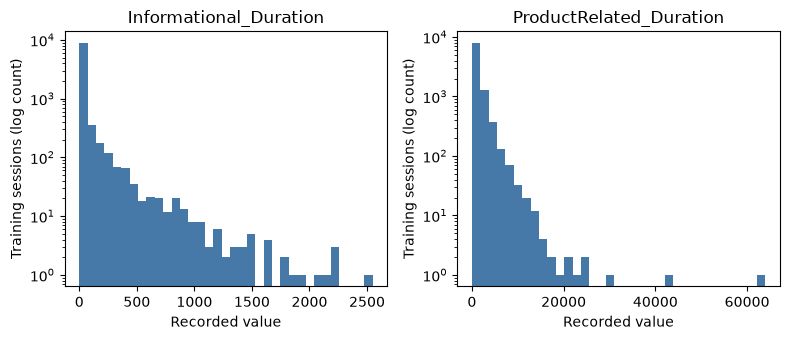

Interpretation: Informational has 78.5% zeros, Informational_Duration 80.5% zeros, and ProductRelated_Duration skew=8.01. These motivate, but do not validate, presence and log1p trials.


In [3]:
Xtr=X_train; ytr=y_train
num_summary=pd.DataFrame({'median':Xtr[NUMERIC_ALL].median(),'zero share':Xtr[NUMERIC_ALL].eq(0).mean(),
                          'skew':Xtr[NUMERIC_ALL].skew(),'buyer median':Xtr.loc[ytr.eq(1),NUMERIC_ALL].median(),
                          'nonbuyer median':Xtr.loc[ytr.eq(0),NUMERIC_ALL].median()})
display(num_summary[['median','zero share','skew']].round(3))
fig,axes=plt.subplots(1,2,figsize=(8,3.5))
for ax,col in zip(axes.flat,['Informational_Duration','ProductRelated_Duration']):
    ax.hist(Xtr[col],bins=35,log=True,color='#4779a8'); ax.set(title=col,xlabel='Recorded value',ylabel='Training sessions (log count)')
plt.tight_layout(); plt.show()
long_tail=num_summary.loc[ACTIVITY,'skew']

print(f'Interpretation: Informational has {num_summary.loc["Informational","zero share"]:.1%} zeros, Informational_Duration {num_summary.loc["Informational_Duration","zero share"]:.1%} zeros, and ProductRelated_Duration skew={num_summary.loc["ProductRelated_Duration","skew"]:.2f}. These motivate, but do not validate, presence and log1p trials.')


## 3. Categorical EDA

**Purpose.** Compare observed buying rates across nominal levels.

**Method.** Summarise sparsity and show Month/VisitorType rates on training rows.

**Implication.** Encode nominal levels in each CV fit; avoid over-interpreting small groups.


In [4]:
cat_summary=[]
for col in CAT:
    tab=Xtr.assign(Revenue=ytr).groupby(col,observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean'))
    cat_summary.append({'feature':col,'levels':len(tab),'small levels <50':int((tab.sessions<50).sum()),
      'small-level sessions':int(tab.loc[tab.sessions<50,'sessions'].sum()),
      'buyer-rate range':f"{tab.buyer_rate.min():.1%}–{tab.buyer_rate.max():.1%}"})
display(pd.DataFrame(cat_summary).set_index('feature')[['levels','small levels <50','buyer-rate range']])
for col in ['Month','VisitorType']:
    tab=Xtr.assign(Revenue=ytr).groupby(col,observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean')).sort_values('sessions',ascending=False)
    print(f'Training group counts and observed buyer rates: {col}')
    display(tab[['sessions','buyer_rate']].round(3))
rare=[]
for col in ['TrafficType','Browser','Region']:
    tab=Xtr.assign(Revenue=ytr).groupby(col,observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean'))
    small=tab[tab.sessions<50]
    rare.append({'feature':col,'levels below n=50':len(small),'total levels':len(tab),
                 'rare-cell rate range':f"{small.buyer_rate.min():.1%}–{small.buyer_rate.max():.1%}" if len(small) else 'none'})
vtm=Xtr.assign(Revenue=ytr).groupby(['VisitorType','Month'],observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean')).reset_index()
special=Xtr.assign(Revenue=ytr).groupby('SpecialDay',observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean'))

print(f'Interpretation: {int((Xtr.Browser.value_counts()<50).sum())} Browser and {int((Xtr.TrafficType.value_counts()<50).sum())} TrafficType levels have fewer than 50 training rows. Fold-fitted pooling is a hypothesis, not a guaranteed gain; all six categories remain nominal.')


,levels,small levels <50,buyer-rate range
feature,,,
Month,10,0,1.4%–24.8%
OperatingSystems,8,3,10.6%–25.0%
Browser,13,4,0.0%–42.9%
Region,9,0,14.2%–17.0%
TrafficType,20,9,0.0%–33.3%
VisitorType,3,0,14.0%–24.7%


Training group counts and observed buyer rates: Month


,sessions,buyer_rate
Month,,
May,2703,0.108
Nov,2360,0.248
Mar,1538,0.103
Dec,1391,0.132
Oct,444,0.221
Sep,368,0.204
Jul,344,0.134
Aug,342,0.178
June,228,0.101


Training group counts and observed buyer rates: VisitorType


,sessions,buyer_rate
VisitorType,,
Returning_Visitor,8443,0.140
New_Visitor,1347,0.247
Other,74,0.176


Interpretation: 4 Browser and 9 TrafficType levels have fewer than 50 training rows. Fold-fitted pooling is a hypothesis, not a guaranteed gain; all six categories remain nominal.


## 4. Predictor relationships and assumptions

**Purpose.** Assess dependence and departure from Gaussian shapes.

**Method.** Check selected within-class correlations and Q–Q plots.

**Implication.** Diagnostics motivate candidates; CV, not visual assumptions alone, evaluates performance.


BounceRates/ExitRates correlations are 0.915 for nonbuyers and 0.723 for buyers; ProductRelated/ProductRelated_Duration are 0.839 and 0.896. These selected differences do not establish unequal full covariance matrices.


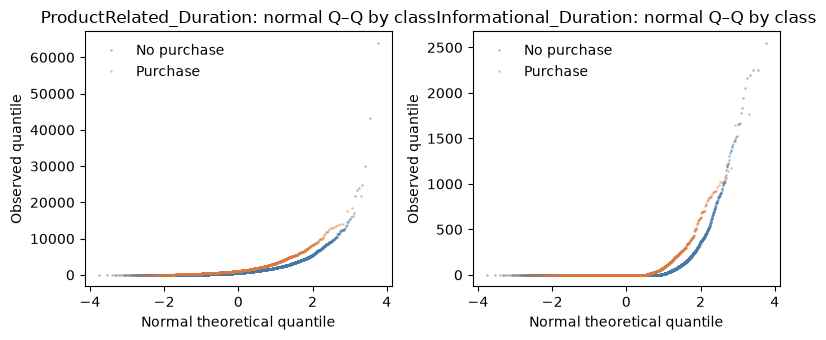

In [5]:
NUM_SAFE=[c for c in NUMERIC_ALL if c!='PageValues']+['Weekend']
for cls in [0,1]:
    corr=Xtr.loc[ytr.eq(cls),NUM_SAFE].corr().abs()
    pairs=corr.where(np.triu(np.ones(corr.shape),k=1).astype(bool)).stack().sort_values(ascending=False).head(5)
print('BounceRates/ExitRates correlations are {:.3f} for nonbuyers and {:.3f} for buyers; ProductRelated/ProductRelated_Duration are {:.3f} and {:.3f}. These selected differences do not establish unequal full covariance matrices.'.format(
 Xtr.loc[ytr.eq(0),['BounceRates','ExitRates']].corr().iloc[0,1],Xtr.loc[ytr.eq(1),['BounceRates','ExitRates']].corr().iloc[0,1],
 Xtr.loc[ytr.eq(0),['ProductRelated','ProductRelated_Duration']].corr().iloc[0,1],Xtr.loc[ytr.eq(1),['ProductRelated','ProductRelated_Duration']].corr().iloc[0,1]))
fig,axes=plt.subplots(1,2,figsize=(8,3.5))
for ax,col in zip(axes,['ProductRelated_Duration','Informational_Duration']):
    for cls,label,color in [(0,'No purchase','#4779a8'),(1,'Purchase','#d97941')]:
        vals=Xtr.loc[ytr.eq(cls),col].to_numpy()
        (osm,osr),_=stats.probplot(vals,dist='norm',fit=True)
        ax.plot(osm,osr,'.',ms=2,alpha=.35,label=label,color=color)
    ax.set(title=f'{col}: normal Q–Q by class',xlabel='Normal theoretical quantile',ylabel='Observed quantile'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

def marginal_elogit(col, bins=8):
    z=pd.DataFrame({'x':Xtr[col],'buyer':ytr}); z['bin']='zero'; positive=z.x.gt(0)
    if positive.any(): z.loc[positive,'bin']=pd.qcut(z.loc[positive,'x'],bins,duplicates='drop').astype(str)
    out=z.groupby('bin',observed=True).agg(n=('buyer','size'),mean_x=('x','mean'),buyers=('buyer','sum'),rate=('buyer','mean')).reset_index()
    out['empirical_logit']=np.log((out.buyers+.5)/(out.n-out.buyers+.5))
    return out.sort_values('mean_x')


In [6]:
# Reuse v2's source variables, data split, folds and basic model-evaluation contract.
# New v3 changes are deliberately isolated in this fold-fitted representation and evaluator.
from sklearn.model_selection import GridSearchCV
from sklearn.calibration import calibration_curve
from sklearn.tree import DecisionTreeClassifier, plot_tree

V3_ART=ARTIFACTS/'prd_v3_6'
V3_ART.mkdir(parents=True,exist_ok=True)
C_GRID=[0.05,0.2,1.0,5.0,20.0]
REG_C_GRID=[0.01,0.05,0.2,1.0,5.0,20.0]
SHRINKAGE_GRID=[0.0,0.1,0.3,0.6,0.9]
RARE_MIN_COUNT=50
INNER_FOLDS=3
FAMILY_ORDER=['Logit','LDA','GaussianNB','BernoulliNB']

class FoldSafeFeatures(BaseEstimator, TransformerMixin):
    """Train-fold-only feature engineering. Categorical levels are never treated as ordinal."""
    def __init__(self, family='Logit', columns=(), log_activity=False,
                 presence=False, rare_pool=False, special_binary=False,
                 drop_features=(), median_cols=(), scale=False,
                 presence_cols=(), log_cols=(), quadratic_cols=(),
                 special_categorical=False, drop_nominal=False,
                 bounce_piecewise=False, bounce_binned=False,
                 winsor_cols=(), avg_product_duration=False):
        self.family=family
        self.columns=columns
        self.log_activity=log_activity
        self.presence=presence
        self.rare_pool=rare_pool
        self.special_binary=special_binary
        self.drop_features=drop_features
        self.median_cols=median_cols
        self.scale=scale
        self.presence_cols=presence_cols
        self.log_cols=log_cols
        self.quadratic_cols=quadratic_cols
        self.special_categorical=special_categorical
        self.drop_nominal=drop_nominal
        self.bounce_piecewise=bounce_piecewise
        self.bounce_binned=bounce_binned
        self.winsor_cols=winsor_cols
        self.avg_product_duration=avg_product_duration

    def _blocks(self,X):
        active=[c for c in self.columns if c not in self.drop_features
                and not (self.drop_nominal and c in CAT)]
        cats=[c for c in CAT if c in active]
        if self.special_categorical and 'SpecialDay' in active:
            cats.append('SpecialDay')
        if self.bounce_binned and 'BounceRates' in active:
            cats.append('BounceRates')
        nums=[c for c in active if c not in cats]
        z=pd.DataFrame(index=X.index)
        for c in nums:
            value=X[c].astype(float)
            if c=='BounceRates' and self.bounce_piecewise:
                z['BounceRates__positive']=(value>0).astype(float)
                z['BounceRates__up_to_001']=np.minimum(value,0.01)
                z['BounceRates__above_001']=np.maximum(value-0.01,0.0)
                continue
            if c in self.winsor_cols:
                # Sequential inheritance: cap first, then preserve an earlier log1p
                # representation rather than silently replacing it with raw capped data.
                capped=value.clip(upper=self.winsor_cutoffs_[c])
                z[c]=(np.log1p(capped) if
                    ((self.log_activity and c in ACTIVITY) or c in self.log_cols)
                    else capped)
                continue
            if self.family=='BernoulliNB':
                if c in self.median_cols:
                    z[c]=(value>self.medians_[c]).astype(float)
                elif c=='Weekend':
                    z[c]=value
                else:
                    z[c]=(value>0).astype(float)
            elif self.special_binary and c=='SpecialDay':
                z[c]=(value>0).astype(float)
            elif (self.log_activity and c in ACTIVITY) or c in self.log_cols:
                z[c]=np.log1p(value)
            else:
                z[c]=value
        if self.presence:
            for c in ('Informational','Informational_Duration'):
                if c in active:
                    z[c+'__positive']=(X[c].astype(float)>0).astype(float)
        for c in self.presence_cols:
            if c in active:
                z[c+'__positive']=(X[c].astype(float)>0).astype(float)
        for c in self.quadratic_cols:
            if c in active:
                z[c+'__squared']=X[c].astype(float)**2
        if self.avg_product_duration:
            # Zero page-count sessions receive 0, without dividing by zero.
            pages=X['ProductRelated'].astype(float).to_numpy()
            seconds=X['ProductRelated_Duration'].astype(float).to_numpy()
            z['ProductRelated__duration_per_page']=np.divide(
                seconds,pages,out=np.zeros_like(seconds,dtype=float),
                where=pages>0)
        cat=pd.DataFrame(index=X.index)
        for c in cats:
            if c=='BounceRates' and self.bounce_binned:
                b=X[c].astype(float)
                values=pd.Series(np.where(b.eq(0),'zero',
                    np.where(b.le(0.01),'low-positive','high-positive')),
                    index=X.index)
            else:
                values=X[c].astype(str)
            if self.rare_pool and c in ('Browser','TrafficType'):
                values=values.where(values.isin(self.major_levels_[c]),'__OTHER__')
            cat[c]=values
        return z,cat

    def fit(self,X,y=None):
        self.n_features_in_=X.shape[1]
        self.feature_names_in_=np.asarray(X.columns,dtype=object)
        self.major_levels_={}
        for c in ('Browser','TrafficType'):
            if c in X and self.rare_pool:
                counts=X[c].astype(str).value_counts()
                self.major_levels_[c]=set(counts.index[counts>=RARE_MIN_COUNT])
        self.medians_={c:float(X[c].median()) for c in self.median_cols}
        self.winsor_cutoffs_={c:float(X[c].quantile(0.99)) for c in self.winsor_cols}
        num,cat=self._blocks(X)
        self.numeric_names_=list(num.columns)
        self.categorical_names_=list(cat.columns)
        self.encoder_=OneHotEncoder(
            drop='first' if self.family in ('Logit','LDA') else None,
            handle_unknown='ignore',sparse_output=False
        )
        if self.categorical_names_:
            self.encoder_.fit(cat)
        transformed=self._encode(num,cat)
        if self.scale:
            self.scaler_=StandardScaler().fit(transformed)
        return self

    def _encode(self,num,cat):
        blocks=[num.to_numpy(dtype=float)]
        if self.categorical_names_:
            blocks.append(self.encoder_.transform(cat))
        Z=np.column_stack(blocks)
        if not np.isfinite(Z).all():
            raise ValueError('Non-finite preprocessing output')
        return Z

    def transform(self,X):
        num,cat=self._blocks(X)
        Z=self._encode(num,cat)
        return self.scaler_.transform(Z) if self.scale else Z

    def get_feature_names_out(self,input_features=None):
        names=list(self.numeric_names_)
        if self.categorical_names_:
            names+=list(self.encoder_.get_feature_names_out(self.categorical_names_))
        return np.asarray(names,dtype=object)


class BackwardSelectedLDA(BaseEstimator, ClassifierMixin):
    """Leakage-free grouped backward source selection inside each outer training fit.

    A fixed set of inner folds evaluates *every candidate removal* from the current
    subset, then chooses subset size by the course's simplest-within-1SE rule.
    Outer validation outcomes are never used in this search.
    """
    def __init__(self, columns=(), inner_folds=3, seed=42, base_config=None):
        self.columns=columns
        self.inner_folds=inner_folds
        self.seed=seed
        self.base_config=base_config

    def fit(self,X,y):
        yv=np.asarray(y,dtype=int)
        cv=StratifiedKFold(n_splits=self.inner_folds,shuffle=True,random_state=self.seed)
        cached=[]
        for fit_idx,val_idx in cv.split(X,yv):
            pre=FoldSafeFeatures(family='LDA',columns=tuple(self.columns),**dict(self.base_config or {}))
            zfit=pre.fit_transform(X.iloc[fit_idx])
            zval=pre.transform(X.iloc[val_idx])
            feat=list(pre.get_feature_names_out())
            groups={}
            for name in self.columns:
                if name in pre.numeric_names_:
                    groups[name]=[i for i,col in enumerate(feat)
                                  if col==name or col.startswith(name+'__')]
                elif name in pre.categorical_names_:
                    groups[name]=[i for i,col in enumerate(feat)
                                  if col.startswith(name+'_')]
                else:
                    groups[name]=[i for i,col in enumerate(feat)
                                  if col.startswith(name+'__')]
                if not groups[name]:
                    raise RuntimeError(f'No encoded columns for {name}')
            all_indices=[i for g in groups.values() for i in g]
            if len(all_indices)!=len(set(all_indices)) or sorted(all_indices)!=list(range(len(feat))):
                raise RuntimeError('Source-group index mapping is not a partition')
            cached.append((zfit,zval,yv[fit_idx],yv[val_idx],groups))

        def cross_validated_score(selected):
            fold_scores=[]
            for zfit,zval,yfit,yval,groups in cached:
                indices=sorted(i for name in selected for i in groups[name])
                clf=LinearDiscriminantAnalysis(solver='svd')
                clf.fit(zfit[:,indices],yfit)
                p=clf.predict_proba(zval[:,indices])[:,1]
                fold_scores.append(float(roc_auc_score(yval,p)))
            a=np.asarray(fold_scores,dtype=float)
            return float(a.mean()),float(a.std(ddof=1)/np.sqrt(len(a))),a.tolist()

        remaining=tuple(self.columns)
        self.selection_path_=[]
        prior=None
        while True:
            if prior is None:
                candidates=[remaining]
            else:
                candidates=[tuple(c for c in remaining if c!=drop) for drop in remaining]
            options=[]
            for option in candidates:
                avg,se,fold_scores=cross_validated_score(option)
                # Maximise AUC; stable tie by original order of the removed source.
                options.append((avg,se,fold_scores,option))
            options.sort(key=lambda x:(-x[0],tuple(self.columns.index(c) for c in x[3])))
            avg,se,fold_scores,chosen=options[0]
            self.selection_path_.append({'source_count':len(chosen),'selected_sources':list(chosen),
                        'inner_mean_auc':avg,'inner_auc_se':se,
                        'inner_fold_aucs':fold_scores})
            remaining=chosen
            prior=True
            if len(remaining)==1:
                break
        best=sorted(self.selection_path_,key=lambda v:(-v['inner_mean_auc'],-v['source_count']))[0]
        self.one_se_cutoff_=best['inner_mean_auc']-best['inner_auc_se']
        eligible=[p for p in self.selection_path_
                  if p['inner_mean_auc']>=self.one_se_cutoff_-1e-14]
        selected=sorted(eligible,key=lambda p:(p['source_count'],-p['inner_mean_auc']))[0]
        self.selected_source_cols_=tuple(selected['selected_sources'])
        self.selected_source_count_=len(self.selected_source_cols_)
        self.inner_selected_auc_=selected['inner_mean_auc']
        self.inner_best_size_=best['source_count']
        self.model_=Pipeline([
            ('pre',FoldSafeFeatures(family='LDA',columns=self.selected_source_cols_,**dict(self.base_config or {}))),
            ('clf',LinearDiscriminantAnalysis(solver='svd'))
        ])
        self.model_.fit(X,y)
        self.named_steps=self.model_.named_steps
        self.classes_=self.model_.named_steps['clf'].classes_
        self.n_features_in_=X.shape[1]
        return self

    def predict_proba(self,X):
        return self.model_.predict_proba(X)

    def predict(self,X):
        return self.model_.predict(X)

def build_model(family,config=None,columns=SAFE):
    cfg=dict(config or {})
    tune=cfg.pop('tune',None)
    backward=bool(cfg.pop('backward_select',False))
    if backward:
        if family!='LDA':
            raise ValueError('Backward selection only supports LDA')
        active=tuple(col for col in columns if col not in cfg.get('drop_features',())
            and not (cfg.get('drop_nominal',False) and col in CAT))
        base_cfg=cfg.copy()
        base_cfg.pop('drop_features',None)
        base_cfg.pop('drop_nominal',None)
        if not active:
            raise ValueError('No active source predictors for backward selection')
        return BackwardSelectedLDA(columns=active,inner_folds=INNER_FOLDS,
                                   seed=SEED,base_config=base_cfg)
    pre=FoldSafeFeatures(family=family,columns=tuple(columns),**cfg)
    if family=='Logit':
        if tune=='logit':
            clf=LogisticRegression(solver='lbfgs',max_iter=1600,tol=1e-6)
        elif tune=='lasso':
            clf=LogisticRegression(penalty='l1',solver='saga',
                                    max_iter=10000,tol=1e-4,random_state=SEED)
        elif tune=='elasticnet':
            clf=LogisticRegression(penalty='elasticnet',l1_ratio=0.5,solver='saga',
                                    max_iter=10000,tol=1e-4,random_state=SEED)
        elif tune is None:
            clf=LogisticRegression(C=np.inf,solver='newton-cg',tol=1e-8,max_iter=2000)
        else:
            raise ValueError(f'Unknown Logit penalty: {tune}')
    elif family=='LDA':
        clf=LinearDiscriminantAnalysis(solver='lsqr' if tune=='lda' else 'svd')
    elif family=='GaussianNB':
        clf=GaussianNB()
    elif family=='BernoulliNB':
        clf=BernoulliNB(binarize=None)
    else:
        raise ValueError(family)
    pipe=Pipeline([('pre',pre),('clf',clf)])
    if tune:
        if tune in ('logit','lasso','elasticnet'):
            params={'clf__C':REG_C_GRID if tune in ('lasso','elasticnet') else C_GRID}
        elif tune=='lda':
            params={'clf__shrinkage':SHRINKAGE_GRID}
        else:
            raise ValueError(f'Unsupported tune: {tune}')
        inner=StratifiedKFold(n_splits=INNER_FOLDS,shuffle=True,random_state=SEED)
        return GridSearchCV(pipe,params,cv=inner,scoring='roc_auc',
                            n_jobs=1,refit=True,error_score='raise')
    return pipe

def make_pipeline(columns,family,estimator=None):
    if estimator is not None:
        raise ValueError('v3 uses explicit configurations, not replacement estimators')
    return build_model(family,{},columns)

def compact_numerical_label(result):
    return result.get('numerical_status','UNKNOWN')

BACKWARD_PATH_ROWS=[]
def tune_is_regularized(model):
    if isinstance(model,GridSearchCV):
        estimator=model.best_estimator_.named_steps['clf']
        return getattr(estimator,'penalty',None) in ('l1','elasticnet')
    return False

def run_spec(label,family,columns,pipeline_factory=None):
    oof=np.full(len(ytr),np.nan)
    folds=[]; warning_rows=[]
    for fold,(fit_idx,val_idx) in enumerate(FOLD_INDICES,1):
        fit_x=Xtr.iloc[fit_idx][columns]
        val_x=Xtr.iloc[val_idx][columns]
        fit_y=ytr.iloc[fit_idx]
        val_y=ytr.iloc[val_idx]
        fitted=pipeline_factory() if pipeline_factory is not None else make_pipeline(columns,family)
        mark_progress(label,fold,'start',n_fit=len(fit_idx),n_validation=len(val_idx))
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            fitted.fit(fit_x,fit_y)
            prob=np.asarray(fitted.predict_proba(val_x)[:,1],dtype=float)
        actual=fitted.best_estimator_ if isinstance(fitted,GridSearchCV) else fitted
        if isinstance(actual,BackwardSelectedLDA):
            for rec in actual.selection_path_:
                BACKWARD_PATH_ROWS.append({'candidate':label,'outer_fold':fold,
                    'source_count':rec['source_count'],
                    'selected_sources':json.dumps(rec['selected_sources']),
                    'inner_mean_auc':rec['inner_mean_auc'],
                    'inner_auc_se':rec['inner_auc_se'],
                    'one_se_cutoff':actual.one_se_cutoff_,
                    'chosen_size':actual.selected_source_count_,
                    'is_selected':rec['source_count']==actual.selected_source_count_})
        clf=actual.named_steps['clf']
        params=['coef_','intercept_','theta_','var_','class_prior_','feature_log_prob_',
                'means_','priors_','scalings_','class_log_prior_']
        finite=all(np.isfinite(np.asarray(getattr(clf,k),dtype=float)).all()
                   for k in params if hasattr(clf,k))
        if not finite or not np.isfinite(prob).all() or np.any((prob<0)|(prob>1)):
            raise RuntimeError(f'{label} fold {fold}: invalid model parameters/probabilities')
        oof[val_idx]=prob
        for w in caught:
            warning_rows.append({'candidate':label,'fold':fold,
                                 'warning_type':w.category.__name__,
                                 'message':str(w.message)[:350]})
        best=fitted.best_params_ if isinstance(fitted,GridSearchCV) else {}
        inner_best_auc=np.nan; inner_one_se_cutoff=np.nan
        if isinstance(fitted,GridSearchCV):
            means=np.asarray(fitted.cv_results_['mean_test_score'],dtype=float)
            best_idx=int(np.argmax(means))
            fold_best=np.asarray([fitted.cv_results_[f'split{i}_test_score'][best_idx]
                                  for i in range(INNER_FOLDS)],dtype=float)
            inner_best_auc=float(means[best_idx])
            inner_one_se_cutoff=float(inner_best_auc-
                                      fold_best.std(ddof=1)/np.sqrt(INNER_FOLDS))
            assert means[int(fitted.best_index_)]>=inner_one_se_cutoff-1e-12
            eligible=[i for i,v in enumerate(means) if v>=inner_one_se_cutoff-1e-12]
            key='clf__shrinkage' if family=='LDA' else 'clf__C'
            values=[float(fitted.cv_results_['params'][i][key]) for i in eligible]
            chosen=float(fitted.best_params_[key])
            assert np.isclose(chosen,max(values) if key=='clf__shrinkage' else min(values))
        row={'candidate':label,'family':family,'fold':fold,'fit_status':'OK',
             'n_fit':len(fit_idx),'n_validation':len(val_idx),
             'roc_auc':float(roc_auc_score(val_y,prob)),
             'average_precision':float(average_precision_score(val_y,prob)),
             'design_rank':np.nan,'design_columns':actual.named_steps['pre'].transform(fit_x.iloc[:1]).shape[1],
             'finite_model_parameters':bool(finite),'finite_probabilities':True,
             'probabilities_in_0_1':True,'inner_cv_best_params':json.dumps(best),
             'inner_cv_best_auc':inner_best_auc,'inner_one_se_cutoff':inner_one_se_cutoff,
             'nonzero_coefficients':(int(np.sum(np.abs(clf.coef_)>1e-10))
                  if family=='Logit' and hasattr(clf,'coef_') else np.nan),
             'selected_source_count':(actual.selected_source_count_
                  if isinstance(actual,BackwardSelectedLDA) else np.nan),
             'selected_source_cols':(json.dumps(actual.selected_source_cols_)
                  if isinstance(actual,BackwardSelectedLDA) else ''),
             'numerical_status':'FINITE_WITH_WARNINGS_REVIEW_REQUIRED' if caught else 'FINITE_FIT'}
        folds.append(row)
        mark_progress(label,fold,'complete',roc_auc=row['roc_auc'])
    if np.isnan(oof).any():
        raise RuntimeError(f'{label}: incomplete OOF coverage')
    auc=np.array([x['roc_auc'] for x in folds],dtype=float)
    ap=np.array([x['average_precision'] for x in folds],dtype=float)
    return {'candidate':label,'family':family,'stage':'all17' if len(columns)==len(ALL) else 'operational16',
            'status':'SCORED','numerical_status':'FINITE_WITH_WARNINGS_REVIEW_REQUIRED' if warning_rows else 'FINITE_FIT',
            'folds':folds,'oof':oof,'warnings':warning_rows,'failure':'',
            'mean_fold_auc':float(auc.mean()),
            'fold_auc_sd':float(auc.std(ddof=1)),
            'fold_auc_se':float(auc.std(ddof=1)/np.sqrt(K)),
            'mean_fold_ap':float(ap.mean()),
            'fold_ap_sd':float(ap.std(ddof=1)),
            'fold_ap_se':float(ap.std(ddof=1)/np.sqrt(K)),
            'pooled_oof_auc':float(roc_auc_score(ytr,oof)),
            'pooled_oof_ap':float(average_precision_score(ytr,oof))}

# The two trees share the existing fold-safe full-indicator nominal encoding.
# Growth settings and seed are fixed by PRD v3.3; only ccp_alpha is tuned.
TREE_FAMILIES={'GiniTree':'gini','EntropyTree':'entropy'}
def tree_pipeline(family,alpha=0.,columns=SAFE):
    assert family in TREE_FAMILIES
    return Pipeline([('pre',FoldSafeFeatures(family=family,columns=tuple(columns))),
       ('clf',DecisionTreeClassifier(criterion=TREE_FAMILIES[family],
           ccp_alpha=float(alpha),max_depth=None,min_samples_leaf=1,
           min_samples_split=2,class_weight=None,random_state=SEED))])

RESULTS={}; FOLD_ROWS=[]; WARNING_ROWS=[]

## 5. Six all-17 first-pass models

**Purpose.** Start with every source predictor.

**Method.** Compare the four established classifiers and full-grown Gini/Entropy trees on the same training folds; none is eligible for operational selection.

**Implication.** This is a diagnostic pass, not the operational model selection.


In [7]:
# A5 — diagnostic first pass, all 17 predictors
for family in ['Logit','GaussianNB','BernoulliNB','LDA',*TREE_FAMILIES]:
    label=f'All17 | {family}'
    print('Fitting',label,flush=True)
    RESULTS[label]=run_spec(label,family,ALL,
        pipeline_factory=(lambda f=family:tree_pipeline(f,0.,ALL)) if family in TREE_FAMILIES else None)
    FOLD_ROWS.extend(RESULTS[label]['folds']); WARNING_ROWS.extend(RESULTS[label]['warnings'])
ALL17=pd.DataFrame([{'candidate':r['candidate'],'scoring status':r['status'],'numerical status':compact_numerical_label(r),'mean ROC-AUC':r.get('mean_fold_auc',np.nan),
 'AUC SD':r.get('fold_auc_sd',np.nan),'AUC SE':r.get('fold_auc_se',np.nan),'mean AP':r.get('mean_fold_ap',np.nan),
 'pooled OOF AUC':r.get('pooled_oof_auc',np.nan),'warnings':len(r['warnings']),'failure':r['failure']} for r in RESULTS.values() if r['stage']=='all17']).set_index('candidate')
display(ALL17[['mean ROC-AUC','AUC SD','mean AP']].round(4))
fold_diag=pd.DataFrame([x for r in RESULTS.values() if r['stage']=='all17' for x in r['folds']])
all17_audit=fold_diag.groupby('candidate').agg(rank_min=('design_rank','min'),rank_max=('design_rank','max'),
    encoded_columns_min=('design_columns','min'),encoded_columns_max=('design_columns','max'),
    all_parameters_finite=('finite_model_parameters','all'),all_probabilities_in_range=('probabilities_in_0_1','all'))
logit_diag=fold_diag[fold_diag.family.eq('Logit')].copy()

assert len(ALL17)==6
ALL17.to_csv(V3_ART/'six_all17_diagnostics.csv')


Fitting All17 | Logit


Fitting All17 | GaussianNB


Fitting All17 | BernoulliNB


Fitting All17 | LDA


Fitting All17 | GiniTree


Fitting All17 | EntropyTree


,mean ROC-AUC,AUC SD,mean AP
candidate,,,
All17 | Logit,0.8897,0.0063,0.6443
All17 | GaussianNB,0.7879,0.0145,0.4334
All17 | BernoulliNB,0.8766,0.0105,0.5345
All17 | LDA,0.8997,0.0033,0.6469
All17 | GiniTree,0.7421,0.0101,0.3850
All17 | EntropyTree,0.7455,0.0102,0.3867


**Interpretation.** `PageValues` may be unavailable when prediction would be required. Exclude it from operational models as a precaution; a strong association alone does not establish leakage.


In [8]:
# PageValues descriptive association on training rows only
pv=Xtr.assign(Revenue=ytr).groupby(Xtr.PageValues.gt(0).map({False:'PageValues = 0',True:'PageValues > 0'})).Revenue.agg(sessions='size',buyers='sum',buyer_rate='mean')
display(pv)
print('The above difference is descriptive. PageValues is excluded from operational predictors because its availability at the intended prediction time is uncertain, not because association proves leakage.')


,sessions,buyers,buyer_rate
PageValues,,,
PageValues = 0,7671,286,0.037283
PageValues > 0,2193,1240,0.565435


The above difference is descriptive. PageValues is excluded from operational predictors because its availability at the intended prediction time is uncertain, not because association proves leakage.


## 6. Six operational baselines

**Purpose.** Evaluate the taught families using the 16 decision-time candidates.

**Method.** Compare four existing baselines and the two full-grown trees using identical folds and fold-fitted nominal encoding; quantify the AUC change from excluding `PageValues`.

**Implication.** Baselines provide the reference for targeted modifications.


In [9]:
# A6 — four operational 16-source-predictor baselines
for family in ['Logit','GaussianNB','BernoulliNB','LDA',*TREE_FAMILIES]:
    label=f'Operational16 | {family}'
    print('Fitting',label,flush=True)
    RESULTS[label]=run_spec(label,family,SAFE,
        pipeline_factory=(lambda f=family:tree_pipeline(f,0.,SAFE)) if family in TREE_FAMILIES else None)
    FOLD_ROWS.extend(RESULTS[label]['folds']); WARNING_ROWS.extend(RESULTS[label]['warnings'])
OP16=pd.DataFrame([{'candidate':r['candidate'],'scoring status':r['status'],'numerical status':compact_numerical_label(r),'mean ROC-AUC':r.get('mean_fold_auc',np.nan),
 'AUC SD':r.get('fold_auc_sd',np.nan),'AUC SE':r.get('fold_auc_se',np.nan),'mean AP':r.get('mean_fold_ap',np.nan),
 'pooled OOF AUC':r.get('pooled_oof_auc',np.nan),'warnings':len(r['warnings']),'failure':r['failure']} for r in RESULTS.values() if r['stage']=='operational16']).set_index('candidate')
display(OP16[['mean ROC-AUC','AUC SD','mean AP']].round(4))
op16_fold_diag=pd.DataFrame([x for r in RESULTS.values() if r['stage']=='operational16' for x in r['folds']])
op16_audit=op16_fold_diag.groupby('candidate').agg(rank_min=('design_rank','min'),rank_max=('design_rank','max'),
    encoded_columns_min=('design_columns','min'),encoded_columns_max=('design_columns','max'),
    all_parameters_finite=('finite_model_parameters','all'),all_probabilities_in_range=('probabilities_in_0_1','all'))
# Direct same-fold AUC changes quantify the effect of omitting PageValues in each family.
comparison=[]
for family in ['Logit','GaussianNB','BernoulliNB','LDA',*TREE_FAMILIES]:
    a=RESULTS[f'All17 | {family}']; b=RESULTS[f'Operational16 | {family}']
    if a['status']=='SCORED' and b['status']=='SCORED':
        for x,y in zip(a['folds'],b['folds']): comparison.append({'family':family,'fold':x['fold'],'AUC all17':x['roc_auc'],'AUC op16':y['roc_auc'],'op16 minus all17':y['roc_auc']-x['roc_auc']})
PAGE_COMPARE=pd.DataFrame(comparison)
PAGE_SUMMARY=PAGE_COMPARE.groupby('family')['op16 minus all17'].agg(['mean','std']).rename(columns={'mean':'mean AUC delta','std':'fold SD'}).round(4)
display(PAGE_SUMMARY[['mean AUC delta']])

print(f'Interpretation: operational Logit starts at CV mean AUC {OP16.loc["Operational16 | Logit","mean ROC-AUC"]:.4f}, versus {ALL17.loc["All17 | Logit","mean ROC-AUC"]:.4f} with PageValues. Exclusion is a timing precaution, not proof of leakage.')

assert len(OP16)==6 and PAGE_COMPARE.family.nunique()==6
ALL17_VS_16=pd.DataFrame([{'family':f,
    'all17_mean_auc':RESULTS[f'All17 | {f}']['mean_fold_auc'],
    'operational16_mean_auc':RESULTS[f'Operational16 | {f}']['mean_fold_auc'],
    'all17_mean_ap':RESULTS[f'All17 | {f}']['mean_fold_ap'],
    'operational16_mean_ap':RESULTS[f'Operational16 | {f}']['mean_fold_ap']}
    for f in [*FAMILY_ORDER,*TREE_FAMILIES]])
OP16.to_csv(V3_ART/'six_operational_baselines.csv')
ALL17_VS_16.to_csv(V3_ART/'all17_vs_operational16.csv',index=False)
PAGE_COMPARE.to_csv(V3_ART/'all17_vs_operational16_folds.csv',index=False)
display(ALL17_VS_16.round(5))
print('Gini and Entropy all-17 diagnostic scores do not enter pruning or winner selection.')


Fitting Operational16 | Logit


Fitting Operational16 | GaussianNB


Fitting Operational16 | BernoulliNB


Fitting Operational16 | LDA


Fitting Operational16 | GiniTree


Fitting Operational16 | EntropyTree


,mean ROC-AUC,AUC SD,mean AP
candidate,,,
Operational16 | Logit,0.7500,0.0122,0.3250
Operational16 | GaussianNB,0.6920,0.0206,0.2574
Operational16 | BernoulliNB,0.7231,0.0182,0.2764
Operational16 | LDA,0.7409,0.0128,0.3165
Operational16 | GiniTree,0.5766,0.0157,0.1902
Operational16 | EntropyTree,0.5797,0.0052,0.1929


,mean AUC delta
family,
BernoulliNB,-0.1534
EntropyTree,-0.1657
GaussianNB,-0.0959
GiniTree,-0.1655
LDA,-0.1588
Logit,-0.1397


Interpretation: operational Logit starts at CV mean AUC 0.7500, versus 0.8897 with PageValues. Exclusion is a timing precaution, not proof of leakage.


,family,all17_mean_auc,operational16_mean_auc,all17_mean_ap,operational16_mean_ap
0,Logit,0.88972,0.75002,0.64432,0.32495
1,LDA,0.89965,0.74088,0.64695,0.31649
2,GaussianNB,0.78795,0.69202,0.43345,0.25745
3,BernoulliNB,0.87656,0.72313,0.53448,0.27635
4,GiniTree,0.74214,0.57663,0.38504,0.19015
5,EntropyTree,0.74547,0.57973,0.38673,0.19288


Gini and Entropy all-17 diagnostic scores do not enter pruning or winner selection.


## 7. Sequential development and the corrected 1-SE rule

**Purpose.** Replay the fixed **v3.0–v3.4 experiment ID order** under the agreed sequential rule: each candidate builds on the currently retained model, and is selected only according to the simplest-within-1-SE comparison. All predeclared transformations, nominal pooling and feature-drop variants remain documented.

**Interpretation.** Unlike the frozen historical v3.4 ledger, these v3.6 candidate scores are newly computed on potentially different parents. A `SKIPPED_INAPPLICABLE` candidate has no AUC to report. The independently pruned trees are unaffected.


In [10]:
# Inherit every historical model definition and rule from the executed v3.3 notebook.
# Only the orchestration order changes: each family is now shown start-to-finish.
# Predeclare the ordered list of single changes. Edits are cumulative only if accepted.
PATHS={
 'Logit':[('L1','log1p six activity magnitudes',{'log_activity':True}),
          ('L2','separate informational positive-presence indicators',{'presence':True}),
          ('L3','fold-fitted pooling of rare Browser/TrafficType levels',{'rare_pool':True}),
          ('L4','standardised L2 logistic with inner-CV C',{'scale':True,'tune':'logit'})],
 'LDA':[('D1','log1p six activity magnitudes',{'log_activity':True}),
        ('D2','binarise SpecialDay>0',{'special_binary':True}),
        ('D3','fold-fitted rare nominal-level pooling',{'rare_pool':True}),
        ('D4','inner-CV covariance shrinkage',{'tune':'lda'})],
 'GaussianNB':[('G1','log1p six activity magnitudes',{'log_activity':True}),
               ('G2','remove BounceRates, retaining ExitRates',{'remove':'BounceRates'}),
               ('G3','remove ProductRelated, retaining duration',{'remove':'ProductRelated'}),
               ('G4','remove SpecialDay Gaussian marginal',{'remove':'SpecialDay'})],
 'BernoulliNB':[('B1','ProductRelated: presence to training-fold median',{'median':'ProductRelated'}),
                ('B2','ProductRelated_Duration: training-fold median',{'median':'ProductRelated_Duration'}),
                ('B3','ExitRates: training-fold median',{'median':'ExitRates'}),
                ('B4','remove BounceRates',{'remove':'BounceRates'})]}

EXTRA_PATHS={
 'Logit':[
  ('L5','add BounceRates squared term, retaining linear term',{'quadratic_cols':('BounceRates',)}),
  ('L6','add Administrative positive-presence indicator',{'presence_cols':('Administrative',)}),
  ('L7','add ProductRelated_Duration positive-presence indicator',{'presence_cols':('ProductRelated_Duration',)})],
 'LDA':[
  ('D5','log1p ProductRelated_Duration only',{'log_cols':('ProductRelated_Duration',)}),
  ('D6','log1p Administrative_Duration only',{'log_cols':('Administrative_Duration',)}),
  ('D7','encode SpecialDay as categorical instead of numeric',{'special_categorical':True})],
 'GaussianNB':[
  ('G5','remove ExitRates, retain BounceRates',{'drop_features':('ExitRates',)}),
  ('G6','remove ProductRelated_Duration, retain ProductRelated',{'drop_features':('ProductRelated_Duration',)}),
  ('G7','log1p ProductRelated_Duration only',{'log_cols':('ProductRelated_Duration',)}),
  ('G8','log1p Administrative_Duration only',{'log_cols':('Administrative_Duration',)}),
  ('G9','exclude all six nominal sources',{'drop_nominal':True})],
 'BernoulliNB':[]
}

V33_EXTRAS={
 'Logit':[
  ('L8','replace BounceRates with fixed 0.01-knot piecewise linear basis',
   {'bounce_piecewise':True}),
  ('L9','encode SpecialDay as fold-fitted nominal categories',
   {'special_categorical':True}),
  ('L10','add safe ProductRelated_Duration per ProductRelated page ratio',
   {'avg_product_duration':True})],
 'LDA':[
  ('D8','log1p ProductRelated count only',{'log_cols':('ProductRelated',)}),
  ('D9','winsorise ProductRelated_Duration at fold-training p99',
   {'winsor_cols':('ProductRelated_Duration',)}),
  ('D10','add Informational positive-presence indicator',
   {'presence_cols':('Informational',)}),
  ('D11','replace BounceRates with zero/low/high categorical bands',
   {'bounce_binned':True})],
 'GaussianNB':[],
 'BernoulliNB':[]
}

V34_EXTRAS={
 'Logit':[
  ('L13','LASSO logistic: fold-scaled L1 penalty and inner-CV C',{'scale':True,'tune':'lasso'}),
  ('L14','Elastic Net logistic: fold-scaled fixed 0.5 L1 ratio and inner-CV C',
       {'scale':True,'tune':'elasticnet'})],
 'LDA':[('D15','Grouped backward LDA selection nested within outer CV',
         {'backward_select':True})],
 'GaussianNB':[],
 'BernoulliNB':[]
}
# PRD v3.6 — sequential one-SE selection.
# This script is included verbatim in notebook Section 7; it operates on the
# fixed v3.4 experiment definitions, data, evaluator and shared outer folds.

ORIGINAL_BUILD_MODEL=build_model

def _inner_one_se_refit(results):
    mean=np.asarray(results['mean_test_score'],dtype=float)
    best=int(np.argmax(mean))
    vals=np.array([results[f'split{i}_test_score'][best] for i in range(INNER_FOLDS)],
                  dtype=float)
    cutoff=float(mean[best]-vals.std(ddof=1)/np.sqrt(INNER_FOLDS))
    candidates=np.flatnonzero(mean>=cutoff-1e-12)
    params=results['params']
    key='clf__shrinkage' if 'clf__shrinkage' in params[0] else 'clf__C'
    if key=='clf__shrinkage':
        return int(max(candidates,key=lambda i:(float(params[int(i)][key]),mean[int(i)])))
    return int(min(candidates,key=lambda i:(float(params[int(i)][key]),-mean[int(i)])))

def build_model(family,config=None,columns=SAFE):
    est=ORIGINAL_BUILD_MODEL(family,config,columns)
    if isinstance(est,GridSearchCV):
        # The same original fixed inner grids, but strongest-penalty within 1 SE.
        est.refit=_inner_one_se_refit
    return est

PATH_FINALISTS={}; PATH_FINAL_CONFIGS={}; ATTEMPTS=[]; STAGE_FINALISTS={}

def active_sources(cfg):
    removed=set(cfg.get('drop_features',()))
    if cfg.get('drop_nominal',False):
        removed.update(CAT)
    return [c for c in SAFE if c not in removed]

def apply_change_to_incumbent(fam,step,base,change):
    cfg=base.copy()
    active=set(active_sources(cfg))
    if 'remove' in change:
        x=change['remove']
        # Preserve the semantic preconditions in the original trial descriptions.
        # A historical "drop X, retain Y" trial cannot silently drop both X and Y.
        required_retained={'G2':('ExitRates',),
            'G3':('ProductRelated_Duration',),
            'G5':('BounceRates',),
            'G6':('ProductRelated',)}
        missing=[c for c in required_retained.get(step,()) if c not in active]
        if missing:
            return None,f'{step} requires already removed retained counterpart(s): {missing}'
        if x not in active:
            return None,f'{x} already dropped'
        cfg['drop_features']=tuple(dict.fromkeys([*cfg.get('drop_features',()),x]))
    elif 'median' in change:
        x=change['median']
        if x not in active:
            return None,f'{x} already dropped'
        if x in cfg.get('median_cols',()):
            return None,f'{x} already median-binarised'
        cfg['median_cols']=tuple(dict.fromkeys([*cfg.get('median_cols',()),x]))
    elif change.get('backward_select',False):
        if len(active)<=1:
            return None,'Backward selection requires at least two remaining sources'
        # D15 substitutes an unshrunk LDA model for an inherited D4 tuned covariance.
        cfg.pop('tune',None)
        cfg['backward_select']=True
    else:
        for key,value in change.items():
            requires={
                'special_binary':['SpecialDay'],
                'special_categorical':['SpecialDay'],
                'bounce_piecewise':['BounceRates'],
                'bounce_binned':['BounceRates'],
                'avg_product_duration':['ProductRelated','ProductRelated_Duration'],
            }.get(key,[])
            if key in ('log_cols','presence_cols','quadratic_cols','winsor_cols','drop_features'):
                requires=list(value)
            # G5/G6 are historical v3.2 drop_features proposals, unlike G2/G3
            # which used the older 'remove' spelling. Enforce their counterpart
            # prerequisites here as well, before creating a candidate.
            if key=='drop_features' and step in ('G5','G6'):
                counterpart={'G5':'BounceRates','G6':'ProductRelated'}[step]
                if counterpart not in active:
                    return None,f'{step} cannot retain previously deleted {counterpart}'
            missing=[c for c in requires if c not in active]
            if missing:
                return None,f'Previously dropped predictor(s) required by {key}: {missing}'
            if key in ('log_cols','presence_cols','quadratic_cols','winsor_cols'):
                already=set(cfg.get(key,()))
                if key=='log_cols' and cfg.get('log_activity'):
                    already.update(ACTIVITY)
                new=[c for c in value if c not in already]
                if not new:
                    return None,f'{key} already applies to these sources'
                cfg[key]=tuple(dict.fromkeys([*cfg.get(key,()),*new]))
            elif key=='drop_features':
                cfg[key]=tuple(dict.fromkeys([*cfg.get(key,()),*value]))
            elif key=='drop_nominal':
                if not set(CAT)&active:
                    return None,'Nominal sources already dropped'
                cfg[key]=bool(value)
            elif key=='log_activity':
                if cfg.get(key,False) or not set(ACTIVITY)&active:
                    return None,'Activity log1p already active or activity sources absent'
                cfg[key]=bool(value)
            elif key=='presence':
                if cfg.get(key,False) or not {'Informational','Informational_Duration'}&active:
                    return None,'Informational presence already active or sources absent'
                cfg[key]=bool(value)
            elif key=='rare_pool':
                if cfg.get(key,False) or not {'Browser','TrafficType'}&active:
                    return None,'Rare category pooling already active or sources absent'
                cfg[key]=bool(value)
            elif key=='special_binary':
                cfg.pop('special_categorical',None)
                cfg[key]=bool(value)
            elif key=='special_categorical':
                cfg.pop('special_binary',None)
                cfg[key]=bool(value)
            elif key=='bounce_piecewise':
                cfg.pop('bounce_binned',None)
                cfg['quadratic_cols']=tuple(x for x in cfg.get('quadratic_cols',())
                                            if x!='BounceRates')
                cfg[key]=bool(value)
            elif key=='bounce_binned':
                cfg.pop('bounce_piecewise',None)
                cfg['quadratic_cols']=tuple(x for x in cfg.get('quadratic_cols',())
                                            if x!='BounceRates')
                cfg[key]=bool(value)
            else:
                # This includes replacing (not stacking) logistic penalties.
                cfg[key]=value
    if cfg==base:
        return None,'No actual change from retained configuration'
    return cfg,None

def model_size(fam,result):
    column='nonzero_coefficients' if fam=='Logit' else 'design_columns'
    vals=[]
    for fr in result['folds']:
        n=fr[column]
        # Existing v3.4 evaluator omits nonzero counts for unpenalised Logit
        # and Ridge; all estimated encoded coefficients count as active.
        if fam=='Logit' and (n is None or pd.isna(n)):
            n=fr['design_columns']
        vals.append(float(n))
    assert len(vals)==K and np.isfinite(vals).all() and min(vals)>=0
    return float(np.mean(vals))

def choose_pair(fam,incumbent,candidate):
    n0=model_size(fam,incumbent);n1=model_size(fam,candidate)
    best=(incumbent if incumbent['mean_fold_auc']>=candidate['mean_fold_auc']
          else candidate)
    cutoff=best['mean_fold_auc']-best['fold_auc_se']
    eligible=[(incumbent,n0,0),(candidate,n1,1)]
    eligible=[(r,n,i) for r,n,i in eligible if r['mean_fold_auc']>=cutoff-1e-12]
    selected=min(eligible,key=lambda v:(v[1],-v[0]['mean_fold_auc'],v[2]))[0]
    return selected['candidate'],float(cutoff),best['candidate']

def run_v36_family(fam):
    prefix={'Logit':'L','LDA':'D','GaussianNB':'G','BernoulliNB':'B'}[fam]
    baseline=f'Operational16 | {fam}'
    retained=baseline;config={}
    b=RESULTS[baseline]
    ATTEMPTS.append({'pathway':fam,'step':prefix+'0','candidate':baseline,
      'parent':'—','trial_version':'v3.1','single_change':'16-source baseline',
      'status':'SCORED','mean_auc':b['mean_fold_auc'],'auc_se':b['fold_auc_se'],
      'mean_ap':b['mean_fold_ap'],'complexity':model_size(fam,b),
      'source_count':16.,'one_se_cutoff':np.nan,'accepted':True,
      'retained_after_step':baseline,'decision':'BASELINE',
      'skip_reason':'','config':json.dumps(config)})
    phases=[('v3.1',PATHS[fam]),('v3.2',EXTRA_PATHS[fam]),
            ('v3.3',V33_EXTRAS[fam]),('v3.4',V34_EXTRAS[fam])]
    for version,changes in phases:
        for step,description,change in changes:
            label=f'{step} | {fam}';parent=retained
            proposal,skip=apply_change_to_incumbent(fam,step,config,change)
            if skip:
                ATTEMPTS.append({'pathway':fam,'step':step,'candidate':label,
                  'parent':parent,'trial_version':version,'single_change':description,
                  'status':'SKIPPED_INAPPLICABLE','mean_auc':np.nan,'auc_se':np.nan,
                  'mean_ap':np.nan,'complexity':np.nan,'source_count':np.nan,
                  'one_se_cutoff':np.nan,'accepted':False,
                  'retained_after_step':parent,'decision':'SKIPPED_INAPPLICABLE',
                  'skip_reason':skip,'config':json.dumps(config)})
                print(f'{label}: SKIPPED_INAPPLICABLE — {skip}',flush=True)
                continue
            assert step!='G7' or 'ProductRelated_Duration' in active_sources(proposal)
            print(f'{label}: recomputing on retained {parent}',flush=True)
            r=run_spec(label,fam,SAFE,
                       pipeline_factory=lambda f=fam,c=proposal:build_model(f,c,SAFE))
            RESULTS[label]=r; FOLD_ROWS.extend(r['folds'])
            WARNING_ROWS.extend(r['warnings'])
            prior=RESULTS[parent]
            selected,cutoff,best=choose_pair(fam,prior,r)
            accepted=(selected==label)
            n0=model_size(fam,prior);n1=model_size(fam,r)
            if accepted:
                retained=label;config=proposal.copy()
            if accepted:
                decision='ACCEPT_SIMPLER' if n1<n0-1e-12 else 'ACCEPT_HIGHER_AUC'
            else:
                decision='RETAIN_SIMPLER' if n0<n1-1e-12 else 'RETAIN_HIGHER_AUC_OR_TIE'
            count=(float(np.mean([x['selected_source_count'] for x in r['folds']]))
                   if step=='D15' else float(len(active_sources(proposal))))
            ATTEMPTS.append({'pathway':fam,'step':step,'candidate':label,
              'parent':parent,'trial_version':version,'single_change':description,
              'status':'SCORED','mean_auc':r['mean_fold_auc'],
              'auc_se':r['fold_auc_se'],'mean_ap':r['mean_fold_ap'],
              'complexity':n1,'source_count':count,
              'one_se_cutoff':cutoff,'best_at_step':best,'accepted':accepted,
              'retained_after_step':retained,'decision':decision,
              'skip_reason':'','config':json.dumps(proposal)})
        STAGE_FINALISTS[(version,fam)]=retained
    PATH_FINALISTS[fam]=retained
    PATH_FINAL_CONFIGS[fam]=config.copy()
    print(f'FINAL {fam}: {retained}; AUC={RESULTS[retained]["mean_fold_auc"]:.5f}',
          flush=True)

def display_family(family):
    history=pd.DataFrame([x for x in ATTEMPTS if x['pathway']==family])
    assert len(history)=={'Logit':13,'LDA':13,'GaussianNB':10,'BernoulliNB':5}[family]
    display(history[['step','trial_version','parent','single_change','status',
        'mean_auc','auc_se','mean_ap','complexity','source_count','one_se_cutoff',
        'decision','retained_after_step','skip_reason']].round(5))


### 7.1 Logistic Regression — 13 planned trials
Logit complexity is the mean number of **active non-intercept coefficients**, including the variable selection induced by LASSO and Elastic Net. L4/L13/L14 use the course-aligned **smallest eligible C** within their inner-CV one-SE range.


In [11]:
run_v36_family('Logit')
display_family('Logit')


L1 | Logit: recomputing on retained Operational16 | Logit


L2 | Logit: recomputing on retained L1 | Logit


L3 | Logit: recomputing on retained L1 | Logit


L4 | Logit: recomputing on retained L3 | Logit


L5 | Logit: recomputing on retained L3 | Logit


L6 | Logit: recomputing on retained L3 | Logit


... (4 outputs left out)

L13 | Logit: recomputing on retained L3 | Logit


L14 | Logit: recomputing on retained L13 | Logit


FINAL Logit: L13 | Logit; AUC=0.75892


,step,trial_version,parent,single_change,status,mean_auc,auc_se,mean_ap,complexity,source_count,one_se_cutoff,decision,retained_after_step,skip_reason
0,L0,v3.1,—,16-source baseline,SCORED,0.75002,0.00544,0.32495,66.4,16.0,NaN,BASELINE,Operational16 | Logit,
1,L1,v3.1,Operational16 | Logit,log1p six activity magnitudes,SCORED,0.75747,0.00608,0.33623,66.4,16.0,0.75139,ACCEPT_HIGHER_AUC,L1 | Logit,
2,L2,v3.1,L1 | Logit,separate informational positive-presence indic...,SCORED,0.75765,0.00582,0.33501,68.4,16.0,0.75183,RETAIN_SIMPLER,L1 | Logit,
3,L3,v3.1,L1 | Logit,fold-fitted pooling of rare Browser/TrafficTyp...,SCORED,0.75834,0.00506,0.33612,55.0,16.0,0.75327,ACCEPT_SIMPLER,L3 | Logit,
4,L4,v3.1,L3 | Logit,standardised L2 logistic with inner-CV C,SCORED,0.75786,0.00509,0.33674,55.0,16.0,0.75327,RETAIN_HIGHER_AUC_OR_TIE,L3 | Logit,
5,L5,v3.2,L3 | Logit,"add BounceRates squared term, retaining linear...",SCORED,0.75926,0.00469,0.33697,56.0,16.0,0.75457,RETAIN_SIMPLER,L3 | Logit,
6,L6,v3.2,L3 | Logit,add Administrative positive-presence indicator,SCORED,0.75826,0.00502,0.33667,56.0,16.0,0.75327,RETAIN_SIMPLER,L3 | Logit,
7,L7,v3.2,L3 | Logit,add ProductRelated_Duration positive-presence ...,SCORED,0.76111,0.00490,0.33793,56.0,16.0,0.75621,RETAIN_SIMPLER,L3 | Logit,
8,L8,v3.3,L3 | Logit,replace BounceRates with fixed 0.01-knot piece...,SCORED,0.75966,0.00435,0.33676,57.0,16.0,0.75531,RETAIN_SIMPLER,L3 | Logit,
9,L9,v3.3,L3 | Logit,encode SpecialDay as fold-fitted nominal categ...,SCORED,0.75943,0.00519,0.33674,59.0,16.0,0.75424,RETAIN_SIMPLER,L3 | Logit,


### 7.2 Linear Discriminant Analysis — 13 planned trials
The D15 backward source-group selector preserves compatible upstream representations and uses **nested inner-fold one-SE subset-size selection**. No full-row categorical encoder or covariance estimator is fitted using outer-fold validation outcomes.


In [12]:
run_v36_family('LDA')
display_family('LDA')
if 'D15 | LDA' in RESULTS:
    d15=RESULTS['D15 | LDA']
    display(pd.DataFrame([{'fold':fr['fold'],'source_count':int(fr['selected_source_count']),
      'selected_source_groups':fr['selected_source_cols'],'outer_auc':fr['roc_auc']}
      for fr in d15['folds']]).round(5))
else:
    print('D15 was skipped because its retained upstream representation made it inapplicable.')


D1 | LDA: recomputing on retained Operational16 | LDA


D2 | LDA: recomputing on retained D1 | LDA


D3 | LDA: recomputing on retained D1 | LDA


D4 | LDA: recomputing on retained D3 | LDA


D5 | LDA: SKIPPED_INAPPLICABLE — log_cols already applies to these sources


D6 | LDA: SKIPPED_INAPPLICABLE — log_cols already applies to these sources


... (5 outputs left out)

D15 | LDA: recomputing on retained D9 | LDA


FINAL LDA: D15 | LDA; AUC=0.73896


,step,trial_version,parent,single_change,status,mean_auc,auc_se,mean_ap,complexity,source_count,one_se_cutoff,decision,retained_after_step,skip_reason
0,D0,v3.1,—,16-source baseline,SCORED,0.74088,0.00571,0.31649,66.4,16.0,NaN,BASELINE,Operational16 | LDA,
1,D1,v3.1,Operational16 | LDA,log1p six activity magnitudes,SCORED,0.74373,0.00638,0.32100,66.4,16.0,0.73735,ACCEPT_HIGHER_AUC,D1 | LDA,
2,D2,v3.1,D1 | LDA,binarise SpecialDay>0,SCORED,0.74320,0.00625,0.32080,66.4,16.0,0.73735,RETAIN_HIGHER_AUC_OR_TIE,D1 | LDA,
3,D3,v3.1,D1 | LDA,fold-fitted rare nominal-level pooling,SCORED,0.74358,0.00593,0.32234,55.0,16.0,0.73735,ACCEPT_SIMPLER,D3 | LDA,
4,D4,v3.1,D3 | LDA,inner-CV covariance shrinkage,SCORED,0.73906,0.00848,0.31944,55.0,16.0,0.73765,RETAIN_HIGHER_AUC_OR_TIE,D3 | LDA,
5,D5,v3.2,D3 | LDA,log1p ProductRelated_Duration only,SKIPPED_INAPPLICABLE,NaN,NaN,NaN,NaN,NaN,NaN,SKIPPED_INAPPLICABLE,D3 | LDA,log_cols already applies to these sources
6,D6,v3.2,D3 | LDA,log1p Administrative_Duration only,SKIPPED_INAPPLICABLE,NaN,NaN,NaN,NaN,NaN,NaN,SKIPPED_INAPPLICABLE,D3 | LDA,log_cols already applies to these sources
7,D7,v3.2,D3 | LDA,encode SpecialDay as categorical instead of nu...,SCORED,0.74418,0.00595,0.32279,59.0,16.0,0.73823,RETAIN_SIMPLER,D3 | LDA,
8,D8,v3.3,D3 | LDA,log1p ProductRelated count only,SKIPPED_INAPPLICABLE,NaN,NaN,NaN,NaN,NaN,NaN,SKIPPED_INAPPLICABLE,D3 | LDA,log_cols already applies to these sources
9,D9,v3.3,D3 | LDA,winsorise ProductRelated_Duration at fold-trai...,SCORED,0.74366,0.00595,0.32244,55.0,16.0,0.73771,ACCEPT_HIGHER_AUC,D9 | LDA,


,fold,source_count,selected_source_groups,outer_auc
0,1,8,"[""Administrative_Duration"", ""ProductRelated_Du...",0.75198
1,2,5,"[""ProductRelated_Duration"", ""BounceRates"", ""Ex...",0.73080
2,3,6,"[""ProductRelated_Duration"", ""BounceRates"", ""Ex...",0.74098
3,4,5,"[""ProductRelated_Duration"", ""BounceRates"", ""Ex...",0.74412
4,5,8,"[""ProductRelated_Duration"", ""BounceRates"", ""Ex...",0.72691


### 7.3 Gaussian Naive Bayes — 10 planned trials
A retained feature deletion cannot be reversed implicitly. **If G6 deletes ProductRelated_Duration and is retained, G7 is skipped**, not scored by reintroducing ProductRelated_Duration.


In [13]:
run_v36_family('GaussianNB')
display_family('GaussianNB')


G1 | GaussianNB: recomputing on retained Operational16 | GaussianNB


G2 | GaussianNB: recomputing on retained Operational16 | GaussianNB


G3 | GaussianNB: recomputing on retained G2 | GaussianNB


G4 | GaussianNB: recomputing on retained G3 | GaussianNB


G5 | GaussianNB: SKIPPED_INAPPLICABLE — G5 cannot retain previously deleted BounceRates


G6 | GaussianNB: SKIPPED_INAPPLICABLE — G6 cannot retain previously deleted ProductRelated


G7 | GaussianNB: recomputing on retained G4 | GaussianNB


G8 | GaussianNB: recomputing on retained G7 | GaussianNB


G9 | GaussianNB: recomputing on retained G8 | GaussianNB


FINAL GaussianNB: G9 | GaussianNB; AUC=0.70276


,step,trial_version,parent,single_change,status,mean_auc,auc_se,mean_ap,complexity,source_count,one_se_cutoff,decision,retained_after_step,skip_reason
0,G0,v3.1,—,16-source baseline,SCORED,0.69202,0.00919,0.25745,72.4,16.0,NaN,BASELINE,Operational16 | GaussianNB,
1,G1,v3.1,Operational16 | GaussianNB,log1p six activity magnitudes,SCORED,0.67163,0.03116,0.23843,72.4,16.0,0.68283,RETAIN_HIGHER_AUC_OR_TIE,Operational16 | GaussianNB,
2,G2,v3.1,Operational16 | GaussianNB,"remove BounceRates, retaining ExitRates",SCORED,0.68882,0.00912,0.25574,71.4,15.0,0.68283,ACCEPT_SIMPLER,G2 | GaussianNB,
3,G3,v3.1,G2 | GaussianNB,"remove ProductRelated, retaining duration",SCORED,0.68599,0.00966,0.25135,70.4,14.0,0.67970,ACCEPT_SIMPLER,G3 | GaussianNB,
4,G4,v3.1,G3 | GaussianNB,remove SpecialDay Gaussian marginal,SCORED,0.68205,0.00980,0.24818,69.4,13.0,0.67633,ACCEPT_SIMPLER,G4 | GaussianNB,
5,G5,v3.2,G4 | GaussianNB,"remove ExitRates, retain BounceRates",SKIPPED_INAPPLICABLE,NaN,NaN,NaN,NaN,NaN,NaN,SKIPPED_INAPPLICABLE,G4 | GaussianNB,G5 cannot retain previously deleted BounceRates
6,G6,v3.2,G4 | GaussianNB,"remove ProductRelated_Duration, retain Product...",SKIPPED_INAPPLICABLE,NaN,NaN,NaN,NaN,NaN,NaN,SKIPPED_INAPPLICABLE,G4 | GaussianNB,G6 cannot retain previously deleted ProductRel...
7,G7,v3.2,G4 | GaussianNB,log1p ProductRelated_Duration only,SCORED,0.70397,0.00945,0.25697,69.4,13.0,0.69451,ACCEPT_HIGHER_AUC,G7 | GaussianNB,
8,G8,v3.2,G7 | GaussianNB,log1p Administrative_Duration only,SCORED,0.70609,0.00886,0.25827,69.4,13.0,0.69723,ACCEPT_HIGHER_AUC,G8 | GaussianNB,
9,G9,v3.2,G8 | GaussianNB,exclude all six nominal sources,SCORED,0.70276,0.00676,0.25332,7.0,7.0,0.69723,ACCEPT_SIMPLER,G9 | GaussianNB,


### 7.4 Bernoulli Naive Bayes — 5 planned trials
Fold-fitted binarisation thresholds and accepted predictor deletions accumulate. The discarded changes do not carry forward.


In [14]:
run_v36_family('BernoulliNB')
display_family('BernoulliNB')


B1 | BernoulliNB: recomputing on retained Operational16 | BernoulliNB


B2 | BernoulliNB: recomputing on retained B1 | BernoulliNB


B3 | BernoulliNB: recomputing on retained B2 | BernoulliNB


B4 | BernoulliNB: recomputing on retained B3 | BernoulliNB


FINAL BernoulliNB: B4 | BernoulliNB; AUC=0.74457


,step,trial_version,parent,single_change,status,mean_auc,auc_se,mean_ap,complexity,source_count,one_se_cutoff,decision,retained_after_step,skip_reason
0,B0,v3.1,—,16-source baseline,SCORED,0.72313,0.00812,0.27635,72.4,16.0,NaN,BASELINE,Operational16 | BernoulliNB,
1,B1,v3.1,Operational16 | BernoulliNB,ProductRelated: presence to training-fold median,SCORED,0.73160,0.00821,0.29185,72.4,16.0,0.72339,ACCEPT_HIGHER_AUC,B1 | BernoulliNB,
2,B2,v3.1,B1 | BernoulliNB,ProductRelated_Duration: training-fold median,SCORED,0.73882,0.00783,0.30613,72.4,16.0,0.73099,ACCEPT_HIGHER_AUC,B2 | BernoulliNB,
3,B3,v3.1,B2 | BernoulliNB,ExitRates: training-fold median,SCORED,0.74809,0.00678,0.31533,72.4,16.0,0.74131,ACCEPT_HIGHER_AUC,B3 | BernoulliNB,
4,B4,v3.1,B3 | BernoulliNB,remove BounceRates,SCORED,0.74457,0.00697,0.31509,71.4,15.0,0.74131,ACCEPT_SIMPLER,B4 | BernoulliNB,


### 7.5 New v3.6 full sequential ledger and provenance
Exactly 41 planned IDs (including four baselines), with each attempt explicitly classified `SCORED` or `SKIPPED_INAPPLICABLE`. Skipped specifications do not generate fold scores. All previous versions remain intact.


In [15]:
ATTEMPTS_DF=pd.DataFrame(ATTEMPTS)
assert len(ATTEMPTS_DF)==41
assert ATTEMPTS_DF.trial_version.value_counts().to_dict()=={
 'v3.1':20,'v3.2':11,'v3.3':7,'v3.4':3}
assert len(PATH_FINALISTS)==4
assert len(RESULTS)==12+int(ATTEMPTS_DF.status.eq('SCORED').sum())-4
assert len(FOLD_ROWS)==K*len(RESULTS)
assert not any(x in RESULTS for x in ATTEMPTS_DF.loc[
    ATTEMPTS_DF.status.eq('SKIPPED_INAPPLICABLE'),'candidate'])
ATTEMPTS_DF['selected_family_finalist']=ATTEMPTS_DF.apply(
    lambda r:r.candidate==PATH_FINALISTS[r.pathway],axis=1)
ATTEMPTS_DF.to_csv(V3_ART/'all_attempts_ledger.csv',index=False)
pd.DataFrame([{'pathway':f,'finalist':PATH_FINALISTS[f],
    'configuration':json.dumps(PATH_FINAL_CONFIGS[f])}
    for f in FAMILY_ORDER]).to_csv(V3_ART/'retained_pathways.csv',index=False)
pd.DataFrame(BACKWARD_PATH_ROWS).to_csv(V3_ART/'backward_lda_selection_paths.csv',index=False)
if 'D15 | LDA' in RESULTS:
    pd.DataFrame([{'candidate':'D15 | LDA','outer_fold':fr['fold'],
      'selected_source_count':int(fr['selected_source_count']),
      'selected_source_groups':fr['selected_source_cols'],'outer_auc':fr['roc_auc']}
      for fr in RESULTS['D15 | LDA']['folds']]).to_csv(V3_ART/'backward_lda_outer_folds.csv',index=False)
print('V3.6 finalists:',PATH_FINALISTS)
print('Fixed history: 41 trial IDs, with',
      int(ATTEMPTS_DF.status.eq('SKIPPED_INAPPLICABLE').sum()),'inapplicable trials.')


V3.6 finalists: {'Logit': 'L13 | Logit', 'LDA': 'D15 | LDA', 'GaussianNB': 'G9 | GaussianNB', 'BernoulliNB': 'B4 | BernoulliNB'}
Fixed history: 41 trial IDs, with 5 inapplicable trials.


## 7B. Classification trees — independently grow and prune Gini and Entropy

**Purpose.** Compare each full-grown 16-source tree with a simpler candidate selected by five-fold ROC-AUC, without introducing manual tree feature transformations.

**Method.** Generate each criterion's training-only cost-complexity path (excluding the terminal root-only candidate), evaluate every distinct alpha on the original shared five folds, and use the 1-SE AUC cutoff, then fewest full-training leaves, then higher CV AUC for equal leaves. Exact ties on both statistics prefer the smaller alpha, a deterministic predeclared convention. Nominal encoding is learned separately within each fitting fold. Neither all-17 tree is eligible for tuning.

**Interpretation.** A smaller tree may reduce overfitting, but pruning need not improve CV AUC. Alpha values across Gini and Entropy have different scales; compare their AUC/AP rather than their penalties.


In [16]:
# Tree CV uses the same FOLD_INDICES as all other models.
# Cache only fold-fitted encodings (no target information from validation folds).
TREE_PATH_ROWS=[]; TREE_FOLD_ROWS=[]; TREE_SELECTED={}; TREE_FINALISTS={}; TREE_FITTED={}
TREE_BASELINE_COMPARISON=[]
for family,criterion in TREE_FAMILIES.items():
    print('Pruning',family,flush=True)
    full_pre=FoldSafeFeatures(family=family,columns=tuple(SAFE))
    z_all=full_pre.fit_transform(Xtr[SAFE],ytr)
    full_clf=DecisionTreeClassifier(criterion=criterion,ccp_alpha=0.,
        max_depth=None,min_samples_leaf=1,min_samples_split=2,
        class_weight=None,random_state=SEED).fit(z_all,ytr)
    raw_alphas=full_clf.cost_complexity_pruning_path(z_all,ytr).ccp_alphas
    # Lecture convention: omit only final root-only path entry; retain zero.
    alphas=np.unique(np.r_[0.,raw_alphas[:-1] if len(raw_alphas)>1 else raw_alphas])
    assert len(alphas)>=1 and alphas[0]==0
    cached=[]
    for fold,(fit_idx,val_idx) in enumerate(FOLD_INDICES,1):
        enc=FoldSafeFeatures(family=family,columns=tuple(SAFE))
        zfit=enc.fit_transform(Xtr.iloc[fit_idx][SAFE],ytr.iloc[fit_idx])
        zval=enc.transform(Xtr.iloc[val_idx][SAFE])
        cached.append((fold,zfit,zval,ytr.iloc[fit_idx].to_numpy(),
                       ytr.iloc[val_idx].to_numpy(),val_idx))
    candidates=[]
    for alpha in alphas:
        alpha=float(alpha)
        trained=clone(full_clf).set_params(ccp_alpha=alpha).fit(z_all,ytr)
        aucs=[]; aps=[]
        for fold,zfit,zval,yfit,yval,val_idx in cached:
            fitted=clone(full_clf).set_params(ccp_alpha=alpha).fit(zfit,yfit)
            prob=fitted.predict_proba(zval)[:,1]
            assert np.isfinite(prob).all() and ((prob>=0)&(prob<=1)).all()
            auc=float(roc_auc_score(yval,prob))
            ap=float(average_precision_score(yval,prob))
            aucs.append(auc); aps.append(ap)
            TREE_FOLD_ROWS.append({'family':family,'ccp_alpha':alpha,'fold':fold,
                'roc_auc':auc,'average_precision':ap})
        scores=np.asarray(aucs)
        candidates.append({'family':family,'criterion':criterion,'ccp_alpha':alpha,
            'mean_auc':float(scores.mean()),'auc_sd':float(scores.std(ddof=1)),
            'auc_se':float(scores.std(ddof=1)/np.sqrt(K)),
            'mean_ap':float(np.mean(aps)),'leaves':int(trained.get_n_leaves()),
            'depth':int(trained.get_depth())})
    # Exact-score tie at the top: smaller alpha, determined before viewing outcomes.
    best=sorted(candidates,key=lambda r:(-r['mean_auc'],r['ccp_alpha']))[0]
    cutoff=best['mean_auc']-best['auc_se']
    eligible=[r for r in candidates if r['mean_auc']>=cutoff-1e-14]
    # First simplest (fewest leaves), then higher AUC; exact tie: lower alpha.
    chosen=sorted(eligible,key=lambda r:(r['leaves'],-r['mean_auc'],r['ccp_alpha']))[0]
    exact_ties=[r for r in eligible
        if r['leaves']==chosen['leaves'] and r['mean_auc']==chosen['mean_auc']]
    for row in candidates:
        row.update(best_mean_auc=best['mean_auc'],best_auc_se=best['auc_se'],
            one_se_cutoff=cutoff,eligible=row in eligible,
            selected=row is chosen,exact_tie_count=len(exact_ties) if row is chosen else 0)
        TREE_PATH_ROWS.append(row)
    label=f'Selected | {family}'
    selected_res=run_spec(label,family,SAFE,
        pipeline_factory=lambda f=family,a=chosen['ccp_alpha']:tree_pipeline(f,a,SAFE))
    RESULTS[label]=selected_res
    FOLD_ROWS.extend(selected_res['folds'])
    WARNING_ROWS.extend(selected_res['warnings'])
    assert np.isclose(selected_res['mean_fold_auc'],chosen['mean_auc'],atol=1e-12,rtol=0)
    assert np.isclose(selected_res['mean_fold_ap'],chosen['mean_ap'],atol=1e-12,rtol=0)
    selected_fit=tree_pipeline(family,chosen['ccp_alpha'],SAFE).fit(Xtr[SAFE],ytr)
    tree=selected_fit.named_steps['clf']
    assert tree.get_n_leaves()==chosen['leaves'] and tree.get_depth()==chosen['depth']
    TREE_FITTED[family]=selected_fit
    TREE_FINALISTS[family]=label
    TREE_SELECTED[family]={'criterion':criterion,'ccp_alpha':chosen['ccp_alpha'],
         'depth':chosen['depth'],'leaves':chosen['leaves'],
         'mean_auc':chosen['mean_auc'],'mean_ap':chosen['mean_ap'],
         'best_mean_auc':best['mean_auc'],'best_auc_se':best['auc_se'],
         'one_se_cutoff':cutoff,'eligible_candidates':len(eligible),
         'total_candidates':len(candidates),'exact_tie_count':len(exact_ties)}
    baseline=RESULTS[f'Operational16 | {family}']
    assert np.isclose(baseline['mean_fold_auc'],candidates[0]['mean_auc'],atol=1e-12,rtol=0)
    TREE_BASELINE_COMPARISON.append({'family':family,'criterion':criterion,
         'baseline_alpha':0.,'selected_alpha':chosen['ccp_alpha'],
         'baseline_leaves':int(full_clf.get_n_leaves()),'selected_leaves':chosen['leaves'],
         'baseline_depth':int(full_clf.get_depth()),'selected_depth':chosen['depth'],
         'baseline_mean_auc':baseline['mean_fold_auc'],'selected_mean_auc':chosen['mean_auc'],
         'baseline_mean_ap':baseline['mean_fold_ap'],'selected_mean_ap':chosen['mean_ap'],
         'auc_change':chosen['mean_auc']-baseline['mean_fold_auc'],
         'one_se_cutoff':cutoff})
    print(f'{family}: {len(candidates)} alphas; best CV AUC {best["mean_auc"]:.5f}; '
          f'1-SE cutoff {cutoff:.5f}; selected alpha={chosen["ccp_alpha"]:.9g}, '
          f'{chosen["leaves"]} leaves, depth {chosen["depth"]}, '
          f'CV AUC {chosen["mean_auc"]:.5f}, AP {chosen["mean_ap"]:.5f}; '
          f'exact alpha tie count={len(exact_ties)}')
TREE_PATH=pd.DataFrame(TREE_PATH_ROWS)
TREE_FOLDS=pd.DataFrame(TREE_FOLD_ROWS)
TREE_BASELINE_SELECTED=pd.DataFrame(TREE_BASELINE_COMPARISON)
TREE_PATH.to_csv(V3_ART/'tree_alpha_paths.csv',index=False,float_format='%.17g')
TREE_FOLDS.to_csv(V3_ART/'tree_alpha_fold_scores.csv',index=False,float_format='%.17g')
TREE_BASELINE_SELECTED.to_csv(V3_ART/'tree_full_vs_selected.csv',index=False)
with (V3_ART/'tree_selection.json').open('w') as out:
    json.dump(TREE_SELECTED,out,indent=2,allow_nan=False)
display(TREE_BASELINE_SELECTED.round(5))
print('Interpretation: the retained pruning candidates were determined by the 1-SE CV AUC rule and full-training leaf counts, not by the reserved test set.')


Pruning GiniTree


GiniTree: 364 alphas; best CV AUC 0.73603; 1-SE cutoff 0.72921; selected alpha=0.00100764152, 8 leaves, depth 4, CV AUC 0.73306, AP 0.30389; exact alpha tie count=1
Pruning EntropyTree


EntropyTree: 358 alphas; best CV AUC 0.74849; 1-SE cutoff 0.74319; selected alpha=0.00128706104, 14 leaves, depth 6, CV AUC 0.74414, AP 0.31300; exact alpha tie count=1


,family,criterion,baseline_alpha,selected_alpha,baseline_leaves,selected_leaves,baseline_depth,selected_depth,baseline_mean_auc,selected_mean_auc,baseline_mean_ap,selected_mean_ap,auc_change,one_se_cutoff
0,GiniTree,gini,0.0,0.00101,1388,8,35,4,0.57663,0.73306,0.19015,0.30389,0.15643,0.72921
1,EntropyTree,entropy,0.0,0.00129,1288,14,36,6,0.57973,0.74414,0.19288,0.31300,0.16441,0.74319


Interpretation: the retained pruning candidates were determined by the 1-SE CV AUC rule and full-training leaf counts, not by the reserved test set.


## 8. Six finalists and model selection
**Purpose.** Compare the four newly selected sequential 1-SE family finalists against the **unchanged** independently 1-SE-pruned Gini and Entropy classification trees.

**Method.** Select the highest mean five-fold training CV ROC-AUC across the six families. Recompute all ROC, PR, reliability, threshold and cost results from the newly selected winner's training OOF probabilities.


,pathway,candidate,mean_auc,auc_sd,auc_se,mean_ap
0,Logit,L13 | Logit,0.75892,0.01134,0.00507,0.34236
1,BernoulliNB,B4 | BernoulliNB,0.74457,0.01558,0.00697,0.31509
2,EntropyTree,Selected | EntropyTree,0.74414,0.01214,0.00543,0.31300
3,LDA,D15 | LDA,0.73896,0.01015,0.00454,0.32340
4,GiniTree,Selected | GiniTree,0.73306,0.01363,0.00609,0.30389
5,GaussianNB,G9 | GaussianNB,0.70276,0.01511,0.00676,0.25332


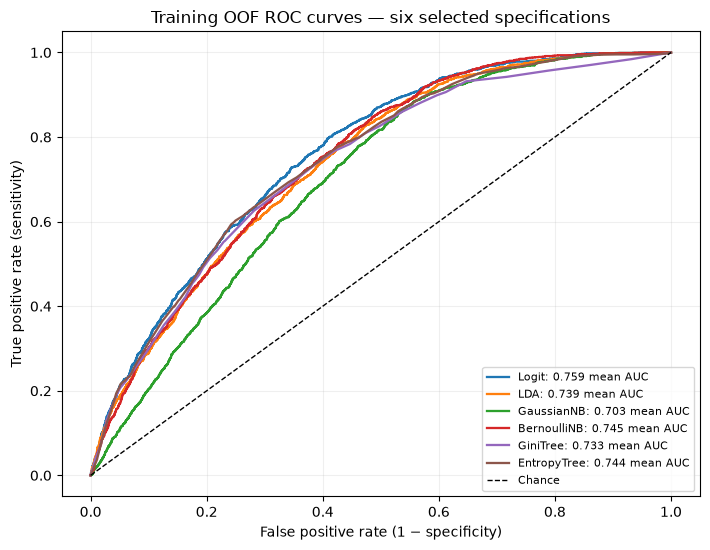

Winner: L13 | Logit | five-fold mean AUC 0.75892
Interpretation: winner AUC exceeds the runner-up by 0.0144; this descriptive gap does not establish significance or calibrated probabilities.
Both selected trees entered the six-way comparison directly.


In [17]:
FINALIST_FAMILIES=[*FAMILY_ORDER,*TREE_FAMILIES]
FINALIST_ROWS=[]
OOF_ROWS=[]
FOLD_SCORE_ROWS=[]
for fam in FINALIST_FAMILIES:
    label=PATH_FINALISTS[fam] if fam in PATH_FINALISTS else TREE_FINALISTS[fam]
    r=RESULTS[label]
    assert r['status']=='SCORED' and len(r['folds'])==K
    coverage=np.zeros(len(ytr),dtype=int)
    for (fit_idx,val_idx),fr in zip(FOLD_INDICES,r['folds']):
        coverage[val_idx]+=1
        yy=ytr.iloc[val_idx].to_numpy()
        pp=r['oof'][val_idx]
        assert abs(roc_auc_score(yy,pp)-fr['roc_auc'])<1e-12
        assert abs(average_precision_score(yy,pp)-fr['average_precision'])<1e-12
        FOLD_SCORE_ROWS.append({'family':fam,'finalist':label,'fold':fr['fold'],
                'roc_auc':fr['roc_auc'],'average_precision':fr['average_precision']})
    assert np.all(coverage==1)
    FINALIST_ROWS.append({'pathway':fam,'candidate':label,'mean_auc':r['mean_fold_auc'],
            'auc_sd':r['fold_auc_sd'],'auc_se':r['fold_auc_se'],
            'mean_ap':r['mean_fold_ap'],'pooled_oof_auc':r['pooled_oof_auc']})
    for row_id,yy,pp in zip(Xtr.index,ytr.to_numpy(),r['oof']):
        OOF_ROWS.append({'finalist':label,'row_id':int(row_id),'observed':int(yy),'oof_probability':float(pp)})
FINALISTS=pd.DataFrame(FINALIST_ROWS).sort_values(['mean_auc','candidate'],ascending=[False,True]).reset_index(drop=True)
WINNER_LABEL=str(FINALISTS.iloc[0]['candidate'])
WINNER_FAMILY=str(FINALISTS.iloc[0]['pathway'])
WINNER_CONFIG=(PATH_FINAL_CONFIGS[WINNER_FAMILY].copy()
    if WINNER_FAMILY in PATH_FINAL_CONFIGS else {'ccp_alpha':TREE_SELECTED[WINNER_FAMILY]['ccp_alpha']})
WINNER_OOF=np.asarray(RESULTS[WINNER_LABEL]['oof'],dtype=float)
BASE_RATE=float(ytr.mean())
FINALISTS.to_csv(V3_ART/'six_finalists.csv',index=False)
pd.DataFrame(FOLD_SCORE_ROWS).to_csv(V3_ART/'finalist_fold_scores.csv',index=False)
pd.DataFrame(OOF_ROWS).to_csv(V3_ART/'finalist_oof_scores.csv',index=False,float_format='%.17g')
display(FINALISTS[['pathway','candidate','mean_auc','auc_sd','auc_se','mean_ap']].round(5))
fig,ax=plt.subplots(figsize=(7.2,5.6))
for fam in FINALIST_FAMILIES:
    label=PATH_FINALISTS[fam] if fam in PATH_FINALISTS else TREE_FINALISTS[fam]
    fpr,tpr,_=roc_curve(ytr,RESULTS[label]['oof'])
    ax.plot(fpr,tpr,lw=1.65,label=f'{fam}: {RESULTS[label]["mean_fold_auc"]:.3f} mean AUC')
ax.plot([0,1],[0,1],'k--',lw=1,label='Chance')
ax.set(xlabel='False positive rate (1 − specificity)',ylabel='True positive rate (sensitivity)',
       title='Training OOF ROC curves — six selected specifications')
ax.legend(loc='lower right',fontsize=8)
ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(V3_ART/'six_finalists_roc.png',dpi=160,bbox_inches='tight')
display(fig);plt.close(fig)
print(f'Winner: {WINNER_LABEL} | five-fold mean AUC {float(FINALISTS.iloc[0]["mean_auc"]):.5f}')
print(f'Interpretation: winner AUC exceeds the runner-up by {float(FINALISTS.iloc[0].mean_auc-FINALISTS.iloc[1].mean_auc):.4f}; this descriptive gap does not establish significance or calibrated probabilities.')
assert len(FINALISTS)==6 and FINALISTS.pathway.nunique()==6
assert set(FINALISTS.pathway)==set(FINALIST_FAMILIES)
assert WINNER_LABEL not in {f'All17 | {f}' for f in FINALIST_FAMILIES}
print('Both selected trees entered the six-way comparison directly.')


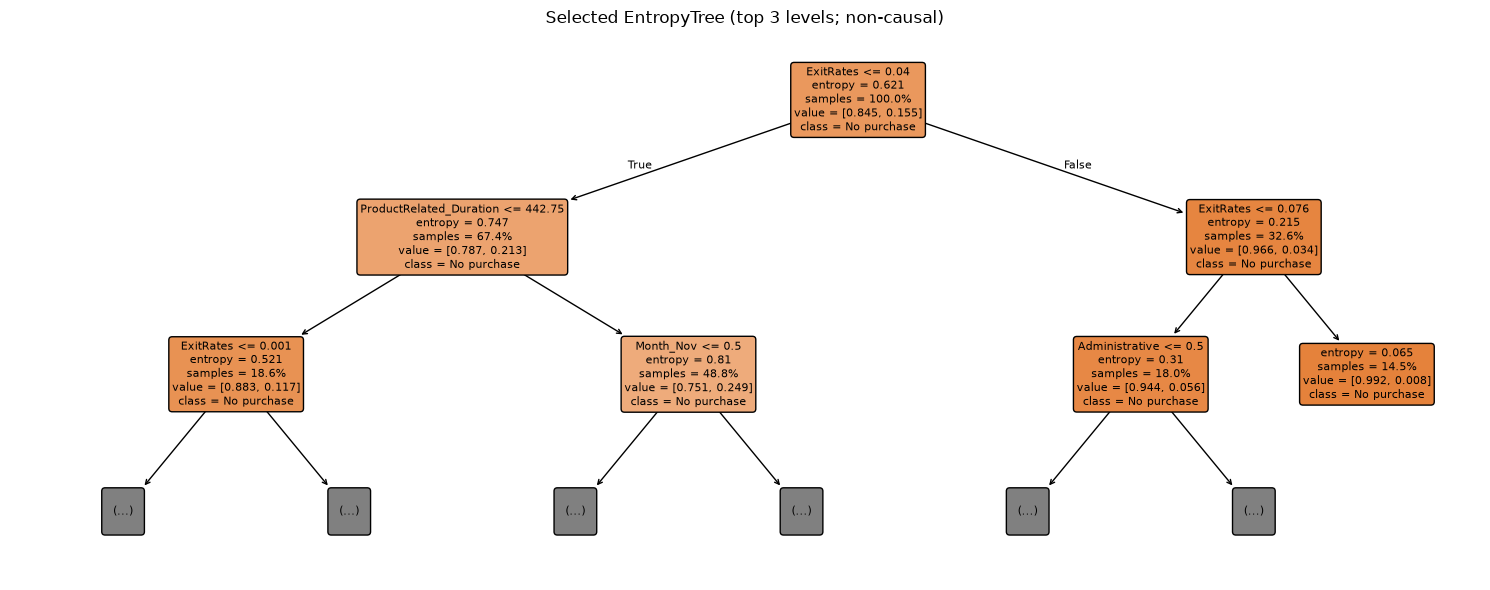

Tree: EntropyTree; root split ExitRates; alpha 0.00128706104; leaves 14; depth 6. Predictive associations, not causal effects.


In [18]:
# Required single illustration after direct six-way model comparison.
illustrated_family=(WINNER_FAMILY if WINNER_FAMILY in TREE_FAMILIES
    else next(p for p in FINALISTS.pathway if p in TREE_FAMILIES))
illustrated=TREE_FITTED[illustrated_family]
tree_clf=illustrated.named_steps['clf']
encoded_features=illustrated.named_steps['pre'].get_feature_names_out()
fig,ax=plt.subplots(figsize=(15,6))
plot_tree(tree_clf,max_depth=2,feature_names=encoded_features,
    class_names=['No purchase','Purchase'],filled=True,rounded=True,
    proportion=True,fontsize=8,ax=ax)
ax.set_title(f'Selected {illustrated_family} (top 3 levels; non-causal)')
fig.tight_layout()
fig.savefig(V3_ART/'selected_tree_top_levels.png',dpi=160,bbox_inches='tight')
display(fig);plt.close(fig)
root_feature=int(tree_clf.tree_.feature[0])
root_name=str(encoded_features[root_feature]) if root_feature>=0 else 'single leaf'
print(f'Tree: {illustrated_family}; root split {root_name}; '
      f'alpha {TREE_SELECTED[illustrated_family]["ccp_alpha"]:.9g}; '
      f'leaves {tree_clf.get_n_leaves()}; depth {tree_clf.get_depth()}. '
      'Predictive associations, not causal effects.')


## 9. Winner's training OOF scores and precision–recall behaviour
**Purpose.** See how buyer/nonbuyer scores overlap and whether minority-class detection is informative.

**Method.** Show one class-separated score histogram and one training OOF precision–recall curve, with the observed buyer prevalence as the no-skill reference. A simple reliability summary follows for the 0.20 decision assumption.

**Interpretation.** ROC-AUC/AP measure ordering, not well-calibrated probabilities. The financial cutoff is only decision-optimal under the stated assumptions *and* sufficiently calibrated probabilities.

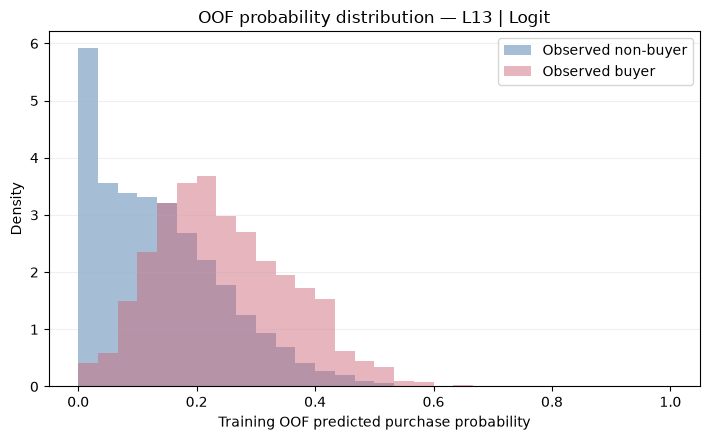

Nonbuyer OOF mean/median=0.1382/0.1208; buyer mean/median=0.2454/0.2306. Scores are below .50 for 99.7% of nonbuyers and 98.2% of buyers; at most 0.0% exceed .90 and the largest is 0.652. This score concentration makes predicted buyer counts sensitive to the chosen cutoff, but does not establish calibration.


In [19]:
fig,ax=plt.subplots(figsize=(7.2,4.5))
for cls,color,name in [(0,'#4477AA','Observed non-buyer'),(1,'#CC6677','Observed buyer')]:
    ax.hist(WINNER_OOF[np.asarray(ytr)==cls],bins=np.linspace(0,1,31),
            density=True,alpha=.48,color=color,label=name)
ax.set(xlabel='Training OOF predicted purchase probability',ylabel='Density',
       title=f'OOF probability distribution — {WINNER_LABEL}')
ax.legend(); ax.grid(axis='y',alpha=.2); fig.tight_layout()
fig.savefig(ARTIFACTS/'training_winner_oof_probability_histogram.png',dpi=180,bbox_inches='tight')
display(fig); plt.close(fig)
hist_rows=[]
for cls,name in [(0,'Observed non-buyer'),(1,'Observed buyer')]:
    values=WINNER_OOF[np.asarray(ytr)==cls]
    hist_rows.append({'observed_group':name,'sessions':len(values),'mean_probability':float(values.mean()),
      'median_probability':float(np.median(values)),'share_below_0.10':float(np.mean(values<.10)),
      'share_below_0.50':float(np.mean(values<.50)),'share_above_0.90':float(np.mean(values>.90)),
      'maximum_probability':float(values.max())})
WINNER_HIST_SUMMARY=pd.DataFrame(hist_rows)
hist_nonbuyer=WINNER_HIST_SUMMARY.loc[WINNER_HIST_SUMMARY.observed_group.eq('Observed non-buyer')].iloc[0]
hist_buyer=WINNER_HIST_SUMMARY.loc[WINNER_HIST_SUMMARY.observed_group.eq('Observed buyer')].iloc[0]
share_high=max(hist_nonbuyer['share_above_0.90'],hist_buyer['share_above_0.90'])
print(f"Nonbuyer OOF mean/median={hist_nonbuyer.mean_probability:.4f}/{hist_nonbuyer.median_probability:.4f}; buyer mean/median={hist_buyer.mean_probability:.4f}/{hist_buyer.median_probability:.4f}. Scores are below .50 for {hist_nonbuyer['share_below_0.50']:.1%} of nonbuyers and {hist_buyer['share_below_0.50']:.1%} of buyers; at most {share_high:.1%} exceed .90 and the largest is {max(hist_nonbuyer['maximum_probability'],hist_buyer['maximum_probability']):.3f}. This score concentration makes predicted buyer counts sensitive to the chosen cutoff, but does not establish calibration.")

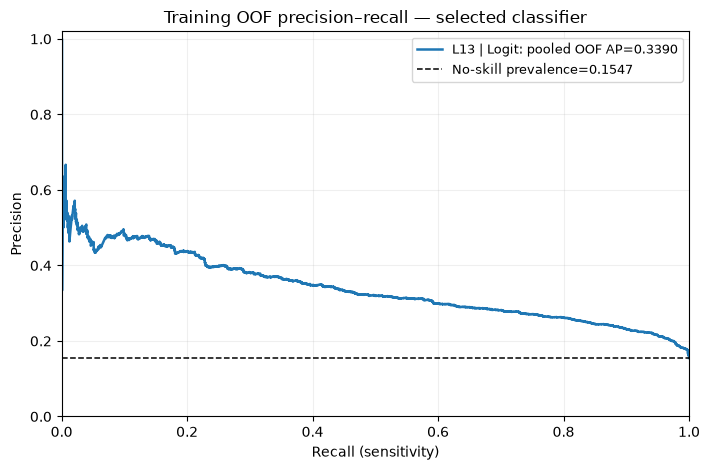

Mean fold AP=0.342356; pooled OOF AP=0.339006; prevalence=0.154704


In [20]:
# A10 — winner OOF precision–recall curve
precision_values,recall_values,_=precision_recall_curve(ytr,WINNER_OOF)
POOLED_AP=float(average_precision_score(ytr,WINNER_OOF))
BASE_RATE=float(ytr.mean())
fig,ax=plt.subplots(figsize=(7.2,4.8))
ax.plot(recall_values,precision_values,lw=1.8,label=f'{WINNER_LABEL}: pooled OOF AP={POOLED_AP:.4f}')
ax.axhline(BASE_RATE,color='black',ls='--',lw=1.1,label=f'No-skill prevalence={BASE_RATE:.4f}')
ax.set(xlabel='Recall (sensitivity)',ylabel='Precision',xlim=(0,1),ylim=(0,1.02),
       title='Training OOF precision–recall — selected classifier')
ax.grid(alpha=.2);ax.legend(fontsize=9);fig.tight_layout()
fig.savefig(V3_ART/'winner_oof_pr.png',dpi=180,bbox_inches='tight')
display(fig);plt.close(fig)
print(f'Mean fold AP={float(FINALISTS.loc[FINALISTS.candidate.eq(WINNER_LABEL),"mean_ap"].iloc[0]):.6f}; pooled OOF AP={POOLED_AP:.6f}; prevalence={BASE_RATE:.6f}')


In [21]:
# Descriptive calibration check, no calibration model is fitted or chosen from holdout.
reliability=pd.DataFrame({'actual':ytr.to_numpy(),'predicted':WINNER_OOF})
reliability['bucket']=pd.cut(reliability.predicted,bins=np.linspace(0,1,11),include_lowest=True)
reliability=reliability.groupby('bucket',observed=True).agg(
    n=('actual','size'),observed_purchase_rate=('actual','mean'),mean_predicted_probability=('predicted','mean')).reset_index()
display(reliability.round(4))
reliability.to_csv(V3_ART/'winner_oof_reliability.csv',index=False)
near=reliability.loc[reliability['mean_predicted_probability'].between(.1,.3)]
print('Interpretation: OOF observed purchase frequency should be compared to mean predicted score around 0.20; upper score buckets are sparse, so probability quality is not established by AUC alone.')
display(near[['bucket','n','observed_purchase_rate','mean_predicted_probability']].round(4))

,bucket,n,observed_purchase_rate,mean_predicted_probability
0,"(-0.001, 0.1]",3700,0.0343,0.0417
1,"(0.1, 0.2]",3021,0.1536,0.1486
2,"(0.2, 0.3]",1935,0.2460,0.2438
3,"(0.3, 0.4]",867,0.3449,0.3430
4,"(0.4, 0.5]",291,0.4570,0.4377
5,"(0.5, 0.6]",48,0.5417,0.5309
6,"(0.6, 0.7]",2,0.5000,0.6336


Interpretation: OOF observed purchase frequency should be compared to mean predicted score around 0.20; upper score buckets are sparse, so probability quality is not established by AUC alone.


,bucket,n,observed_purchase_rate,mean_predicted_probability
1,"(0.1, 0.2]",3021,0.1536,0.1486
2,"(0.2, 0.3]",1935,0.2460,0.2438


## 10. Four threshold references
**Purpose.** Compare classification trade-offs with the hypothetical upselling decision.

**Method.** A prediction of Buy occurs if **p ≥ t**. Use the training buyer prevalence, 0.500, the nearest empirical sensitivity–specificity crossover, and the **fixed assumption-derived 0.200**. Here false positives mean contacting nonbuyers, whereas false negatives mean leaving actual buyers without upsell assistance.

**Payoffs (hypothetical, not observed).** S$3 per agent contact; conditional upsell probability 30% and incremental gross margin S$50. Expected net benefit of contacting an actual buyer = 0.3×50−3 = **S$12**; contacting a nonbuyer = **−S$3**. Thus relative error costs C_FP=3, C_FN=12, and t*=3/(3+12)=**0.20**. Equivalently, contact when 15p−3 > 0 (with equality classified Buy for reproducibility). These costs do not measure any intervention effect from UCI.

,reference,threshold,TP,FP,TN,FN,sensitivity,specificity,precision,hypothetical_relative_loss_SGD
0,Training prevalence,0.1547,1176,3272,5066,350,0.7706,0.6076,0.2644,14016
1,Conventional 0.500,0.5000,27,23,8315,1499,0.0177,0.9972,0.5400,18057
2,Sensitivity–specificity crossover,0.1810,1044,2632,5706,482,0.6841,0.6843,0.2840,13680
3,Cost-based (hypothetical),0.2000,935,2208,6130,591,0.6127,0.7352,0.2975,13716


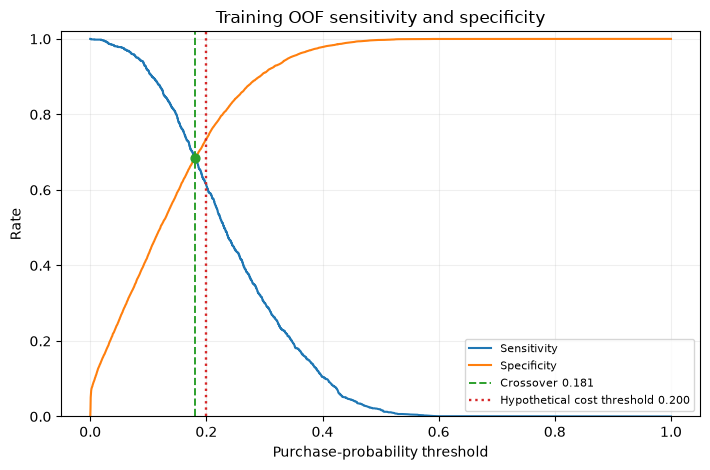

Financial threshold 0.20 is fixed independently of observed confusion matrices.
Interpretation: at 0.20, 935 buyers would be contacted and 2,208 nonbuyers contacted in training OOF predictions; this is a hypothetical cost trade-off, not observed upsell value.


In [22]:
def threshold_measures(y_true,prob,threshold):
    true=np.asarray(y_true,dtype=int)
    pred=(np.asarray(prob,dtype=float)>=float(threshold)).astype(int)
    tn,fp,fn,tp=confusion_matrix(true,pred,labels=[0,1]).ravel()
    return {'threshold':float(threshold),'TP':int(tp),'FP':int(fp),'TN':int(tn),'FN':int(fn),
            'sensitivity':float(tp/(tp+fn)),'specificity':float(tn/(tn+fp)),
            'precision':float(tp/(tp+fp)) if tp+fp else np.nan,
            'hypothetical_relative_loss_SGD':int(3*fp+12*fn)}
_,_,roc_candidates=roc_curve(ytr,WINNER_OOF,drop_intermediate=False)
cutoffs=np.unique(np.r_[roc_candidates[np.isfinite(roc_candidates)&(roc_candidates>=0)&(roc_candidates<=1)],0.,1.])
THRESHOLD_CURVE=pd.DataFrame([threshold_measures(ytr,WINNER_OOF,t) for t in cutoffs])
THRESHOLD_CURVE['gap']=(THRESHOLD_CURVE.sensitivity-THRESHOLD_CURVE.specificity).abs()
CROSSOVER=THRESHOLD_CURVE.sort_values(['gap','threshold'],kind='stable').iloc[0]
CROSSOVER_THRESHOLD=float(CROSSOVER.threshold)
THRESHOLD_REFS=[('Training prevalence',BASE_RATE),('Conventional 0.500',0.5),
                ('Sensitivity–specificity crossover',CROSSOVER_THRESHOLD),
                ('Cost-based (hypothetical)',0.2)]
THRESHOLD_TABLE=pd.DataFrame([{'reference':label,**threshold_measures(ytr,WINNER_OOF,t)}
                              for label,t in THRESHOLD_REFS])
assert len(THRESHOLD_TABLE)==4
assert THRESHOLD_TABLE[['TP','FP','TN','FN']].sum(axis=1).eq(len(ytr)).all()
assert np.isclose(THRESHOLD_TABLE.loc[3,'threshold'],0.2)
THRESHOLD_TABLE.to_csv(V3_ART/'four_threshold_references.csv',index=False)
THRESHOLD_CURVE.to_csv(V3_ART/'threshold_curves.csv',index=False)
display(THRESHOLD_TABLE.round(4))
fig,ax=plt.subplots(figsize=(7.2,4.8))
ax.plot(THRESHOLD_CURVE.threshold,THRESHOLD_CURVE.sensitivity,label='Sensitivity')
ax.plot(THRESHOLD_CURVE.threshold,THRESHOLD_CURVE.specificity,label='Specificity')
ax.axvline(CROSSOVER_THRESHOLD,ls='--',color='tab:green',lw=1.4,label=f'Crossover {CROSSOVER_THRESHOLD:.3f}')
ax.axvline(0.2,ls=':',color='tab:red',lw=1.7,label='Hypothetical cost threshold 0.200')
ax.scatter([CROSSOVER_THRESHOLD],[float(CROSSOVER.sensitivity)],color='tab:green',s=40,zorder=5)
ax.set(xlabel='Purchase-probability threshold',ylabel='Rate',ylim=(0,1.02),
       title='Training OOF sensitivity and specificity')
ax.grid(alpha=.2);ax.legend(fontsize=8);fig.tight_layout()
fig.savefig(V3_ART/'sensitivity_specificity.png',dpi=160,bbox_inches='tight')
display(fig);plt.close(fig)
print('Financial threshold 0.20 is fixed independently of observed confusion matrices.')
print(f'Interpretation: at 0.20, {int(THRESHOLD_TABLE.iloc[3].TP):,} buyers would be contacted and {int(THRESHOLD_TABLE.iloc[3].FP):,} nonbuyers contacted in training OOF predictions; this is a hypothetical cost trade-off, not observed upsell value.')

## 11. Cost-assumption sensitivity (no revenue simulation)
**Purpose.** Show how the hypothetical decision changes when the unknown upsell rate differs.

**Method.** Keep the S$3 contact cost and S$50 incremental gross margin fixed. Set conditional upsell success q=20%, 30% or 40%. Theoretical threshold t=s/(q×g), provided the assumed upsell benefit exceeds contact cost.

**Interpretation.** These are *input assumptions*, not estimated purchase uplift. The UCI data contain no agent assignments or upsell outcomes.

In [23]:
COST_SENSITIVITY=pd.DataFrame([{'assumed_upsell_success_q':q,'agent_cost_SGD':3.,
 'incremental_gross_margin_SGD':50.,'net_TP_value_SGD':q*50-3,
 'C_FP_SGD':3.,'C_FN_SGD':q*50-3.,
 'theoretical_probability_cutoff':3/(q*50)}
 for q in [.20,.30,.40]])
assert np.allclose(COST_SENSITIVITY.theoretical_probability_cutoff,[.30,.20,.15])
display(COST_SENSITIVITY.round(4))
COST_SENSITIVITY.to_csv(V3_ART/'upsell_sensitivity.csv',index=False)

,assumed_upsell_success_q,agent_cost_SGD,incremental_gross_margin_SGD,net_TP_value_SGD,C_FP_SGD,C_FN_SGD,theoretical_probability_cutoff
0,0.2,3.0,50.0,7.0,3.0,7.0,0.30
1,0.3,3.0,50.0,12.0,3.0,12.0,0.20
2,0.4,3.0,50.0,17.0,3.0,17.0,0.15


## 12. Historically reused reserved check and final full-data refit
**Purpose.** Evaluate the fully training-selected v3.6 winner on the historically consulted reserved rows and refit the identical specification on the full dataset.

**Qualification.** These reserved observations have been inspected in earlier project versions; the check is **not independent over the project history**. Do not revise the winner or thresholds based on the reserved result.


In [24]:
# Independent v3.6 numerical and sequential selection audit.
def independently_audit_training_results():
    assert len(ATTEMPTS_DF)==41
    checked=0; decisions=0
    for label,result in RESULTS.items():
        assert len(result['folds'])==K
        for (_,vidx),fr in zip(FOLD_INDICES,result['folds']):
            yy=ytr.iloc[vidx].to_numpy()
            pp=result['oof'][vidx]
            assert np.isclose(roc_auc_score(yy,pp),fr['roc_auc'],atol=1e-12,rtol=0)
            assert np.isclose(average_precision_score(yy,pp),fr['average_precision'],
                              atol=1e-12,rtol=0)
            checked+=1
        values=np.asarray([x['roc_auc'] for x in result['folds']],float)
        assert np.isclose(values.mean(),result['mean_fold_auc'],atol=1e-12,rtol=0)
        assert np.isclose(values.std(ddof=1)/np.sqrt(K),result['fold_auc_se'],atol=1e-12,rtol=0)
    for fam in FAMILY_ORDER:
        entries=ATTEMPTS_DF.loc[ATTEMPTS_DF.pathway.eq(fam)]
        latest=f'Operational16 | {fam}'
        for row in entries.iloc[1:].itertuples():
            assert row.parent==latest
            if row.status=='SKIPPED_INAPPLICABLE':
                assert row.candidate not in RESULTS and bool(row.skip_reason)
                assert row.retained_after_step==latest
                continue
            selected,cutoff,best=choose_pair(fam,RESULTS[row.parent],RESULTS[row.candidate])
            assert row.retained_after_step==selected
            assert np.isclose(row.one_se_cutoff,cutoff,atol=1e-12,rtol=0)
            assert (row.candidate==selected)==row.accepted
            decisions+=1;latest=selected
        assert latest==PATH_FINALISTS[fam]
    if bool(ATTEMPTS_DF.set_index('step').loc['G6','accepted']):
        assert ATTEMPTS_DF.set_index('step').loc['G7','status']=='SKIPPED_INAPPLICABLE'
        assert 'G7 | GaussianNB' not in RESULTS
    if 'D15 | LDA' in RESULTS:
        for fold in range(1,K+1):
            path=[p for p in BACKWARD_PATH_ROWS if p['outer_fold']==fold]
            best=max(path,key=lambda p:p['inner_mean_auc'])
            cutoff=best['inner_mean_auc']-best['inner_auc_se']
            chosen=next(p for p in path if p['is_selected'])
            assert chosen['source_count']==min(p['source_count'] for p in path
                                               if p['inner_mean_auc']>=cutoff-1e-14)
    for row in THRESHOLD_TABLE.itertuples():
        res=threshold_measures(ytr,WINNER_OOF,row.threshold)
        for key in ('TP','FP','TN','FN'):
            assert res[key]==getattr(row,key)
    for fam in TREE_FAMILIES:
        p=TREE_PATH.loc[TREE_PATH.family.eq(fam)]
        best=p.sort_values(['mean_auc','ccp_alpha'],ascending=[False,True]).iloc[0]
        candidates=p.loc[p.mean_auc.ge(best.mean_auc-best.auc_se-1e-14)]
        selected=candidates.sort_values(['leaves','mean_auc','ccp_alpha'],
                                      ascending=[True,False,True]).iloc[0]
        assert np.isclose(selected.ccp_alpha,TREE_SELECTED[fam]['ccp_alpha'],atol=1e-16,rtol=0)
    return {'status':'PASS','planned_trial_ids':41,
      'scored_family_trials':int(ATTEMPTS_DF.status.eq('SCORED').sum()),
      'skipped_inapplicable':int(ATTEMPTS_DF.status.eq('SKIPPED_INAPPLICABLE').sum()),
      'sequential_decisions_verified':decisions,
      'cv_designs_verified':len(RESULTS),'cv_fold_scores_verified':checked,
      'backward_subset_path_entries':len(BACKWARD_PATH_ROWS),
      'tree_alpha_candidates':len(TREE_PATH),'tree_alpha_folds':len(TREE_FOLDS),
      'winner':WINNER_LABEL,'historically_pristine_holdout':False,
      'reserved_used_for_model_selection':False}
TRAINING_AUDIT=independently_audit_training_results()
with (V3_ART/'independent_training_audit.json').open('w') as f:
    json.dump(TRAINING_AUDIT,f,indent=2,allow_nan=False)
print('Independent v3.6 training audit:',TRAINING_AUDIT)

def validate_fitted_model(model,X,description):
    actual=model.best_estimator_ if isinstance(model,GridSearchCV) else model
    if isinstance(actual,BackwardSelectedLDA):
        actual=actual.model_
    estimator=actual.named_steps['clf']
    numbers=[np.asarray(getattr(estimator,k),dtype=float)
        for k in ('coef_','intercept_','theta_','var_','class_prior_','feature_log_prob_','means_','priors_')
        if hasattr(estimator,k)]
    if isinstance(estimator,DecisionTreeClassifier):
        numbers=[np.asarray(estimator.tree_.impurity,float),
                 np.asarray(estimator.tree_.value,float),
                 np.asarray(estimator.tree_.threshold[estimator.tree_.feature>=0],float)]
    if not numbers or not all(np.isfinite(a).all() for a in numbers):
        raise RuntimeError(f'{description}: finite parameter audit failed')
    sample=model.predict_proba(X)[:,1]
    if not np.isfinite(sample).all() or ((sample<0)|(sample>1)).any():
        raise RuntimeError(f'{description}: invalid probability output')
    design=actual.named_steps['pre'].transform(X)
    n_cols=int(design.shape[1])
    rank=int(np.linalg.matrix_rank(design[:min(3000,len(design))]))
    max_coef=(float(np.max(np.abs(estimator.coef_))) if hasattr(estimator,'coef_') else None)
    return {'description':description,'finite_parameters':True,
            'encoded_columns':n_cols,'sample_design_rank':rank,
            'max_absolute_coefficient':max_coef,
            'probability_min':float(sample.min()),'probability_max':float(sample.max()),
            'chosen_inner_CV_params':model.best_params_ if isinstance(model,GridSearchCV) else {}}

SELECTED_TRAIN_MODEL=(tree_pipeline(WINNER_FAMILY,WINNER_CONFIG['ccp_alpha'],SAFE)
    if WINNER_FAMILY in TREE_FAMILIES else build_model(WINNER_FAMILY,WINNER_CONFIG,SAFE))
with warnings.catch_warnings(record=True) as train_warnings:
    warnings.simplefilter('always')
    SELECTED_TRAIN_MODEL.fit(Xtr[SAFE],ytr)
TRAIN_AUDIT=validate_fitted_model(SELECTED_TRAIN_MODEL,Xtr[SAFE],'Frozen training fit')
if any(issubclass(w.category,ConvergenceWarning) for w in train_warnings):
    raise RuntimeError('Frozen training fit convergence warning; inspect before external claims')
print('Frozen training fit passed parameter and probability checks.')

# Do not access any holdout outcome until the winner, four thresholds and training refit
# are fully frozen above. The source is re-read, avoiding any earlier holdout exposure.
reserved=pd.read_csv(data_path)
reserved.insert(0,'_row_id',np.arange(len(reserved),dtype=int))
reserved=reserved.set_index('_row_id').loc[test_ids]
X_test=reserved[SAFE].copy()
X_test[CAT]=X_test[CAT].astype('string')
X_test['Weekend']=X_test['Weekend'].astype(int)
y_test=reserved[TARGET].astype(int)
del reserved
assert len(X_test)==2466 and len(y_test)==2466
test_prob=np.asarray(SELECTED_TRAIN_MODEL.predict_proba(X_test)[:,1],dtype=float)
TEST_AUDIT={'n_test':int(len(y_test)),
   'roc_auc':float(roc_auc_score(y_test,test_prob)),
   'average_precision':float(average_precision_score(y_test,test_prob)),
   'cost_threshold_0_20':threshold_measures(y_test,test_prob,.20)}
display(pd.DataFrame([{'sample':'Reserved v3.6 check (historically previously used)',
            'n':TEST_AUDIT['n_test'],'ROC-AUC':TEST_AUDIT['roc_auc'],
            'AP':TEST_AUDIT['average_precision'],**TEST_AUDIT['cost_threshold_0_20']}]).round(4))
print('This v3.6 reserved check was examined once AFTER freezing the training selection. Prior historical reuse prevents a pristine-independent-test claim.')

# Final all-data refit uses the same selected pathway recipe, no new model selection.
all_rows=pd.read_csv(data_path)
assert len(all_rows)==12330 and set(all_rows.columns)==EXPECTED
all_rows[CAT]=all_rows[CAT].astype('string')
all_rows['Weekend']=all_rows['Weekend'].astype(int)
FINAL_PIPELINE=(tree_pipeline(WINNER_FAMILY,WINNER_CONFIG['ccp_alpha'],SAFE)
    if WINNER_FAMILY in TREE_FAMILIES else build_model(WINNER_FAMILY,WINNER_CONFIG,SAFE))
with warnings.catch_warnings(record=True) as final_warnings:
    warnings.simplefilter('always')
    FINAL_PIPELINE.fit(all_rows[SAFE],all_rows[TARGET].astype(int))
FINAL_AUDIT=validate_fitted_model(FINAL_PIPELINE,all_rows[SAFE],'Final all-data refit')
if any(issubclass(w.category,ConvergenceWarning) for w in final_warnings):
    raise RuntimeError('Final full-data refit convergence warning; inspect before external claims')

RUN_METADATA={'prd':'v3.6','data_sha256':source_hash,
 'random_state':SEED,'training_rows':len(ytr),'test_rows':len(y_test),
 'final_rows':len(all_rows),'cv_folds':K,'inner_folds':INNER_FOLDS,
 'selected_model':WINNER_LABEL,'selected_family':WINNER_FAMILY,
 'selected_recipe':WINNER_CONFIG,'stage_finalists':{ver:{fam:STAGE_FINALISTS[(ver,fam)] for fam in FAMILY_ORDER}
       for ver in ('v3.1','v3.2','v3.3','v3.4')},
 'updated_v36_path_finalists':PATH_FINALISTS,
 'sequential_selection_rule':'best_auc_minus_best_SE_then_simplest',
 'planned_trial_ids':len(ATTEMPTS_DF),
 'skipped_trial_ids':ATTEMPTS_DF.loc[
    ATTEMPTS_DF.status.eq('SKIPPED_INAPPLICABLE'),'step'].tolist(),
 'six_finalists':FINALISTS.candidate.tolist(),'tree_selection':TREE_SELECTED,
 'test_check':TEST_AUDIT,'train_fit_audit':TRAIN_AUDIT,'final_fit_audit':FINAL_AUDIT,
 'train_warnings':[str(w.message) for w in train_warnings],
 'final_warnings':[str(w.message) for w in final_warnings],
 'historically_pristine_holdout':False,
 'training_evidence_audit':TRAINING_AUDIT,
 'd15_outer_selected_sources':([
    {'fold':int(fr['fold']),'source_count':int(fr['selected_source_count']),
     'sources':json.loads(fr['selected_source_cols'])}
    for fr in RESULTS['D15 | LDA']['folds']] if 'D15 | LDA' in RESULTS else []),
 'versions':{'python':platform.python_version(),'pandas':pd.__version__,
            'numpy':np.__version__,'scipy':scipy.__version__,'sklearn':sklearn.__version__}}
with (V3_ART/'run_metadata.json').open('w') as f:
    json.dump(RUN_METADATA,f,indent=2,allow_nan=False,default=str)
pd.DataFrame(FOLD_ROWS).to_csv(V3_ART/'all_attempt_fold_scores.csv',index=False)
pd.DataFrame(WARNING_ROWS).to_csv(V3_ART/'fit_warnings.csv',index=False)
pd.DataFrame({'row_id':Xtr.index,'observed':ytr.to_numpy(),
              'winner_oof_probability':WINNER_OOF}).to_csv(V3_ART/'winner_oof.csv',index=False)
pd.DataFrame({'row_id':test_ids,'observed':y_test.to_numpy(),
              'test_probability':test_prob}).to_csv(V3_ART/'frozen_holdout_scores.csv',index=False)
print('Final all-data fit verified for:',WINNER_LABEL)
print('Interpretation: reserved-set ROC-AUC is a version-specific check, not independent of earlier project exploration; no specifications were revised after seeing this result.')
with (V3_ART/'final_specification.json').open('w') as out:
    json.dump({'winner':WINNER_LABEL,'family':WINNER_FAMILY,
       'configuration':WINNER_CONFIG,'test_evaluated_only_after_training_freeze':True},
       out,indent=2,allow_nan=False)
pd.DataFrame({'row_id':train_ids,'partition':'train'}).to_csv(V3_ART/'train_row_ids.csv',index=False)
pd.DataFrame({'row_id':test_ids,'partition':'test'}).to_csv(V3_ART/'test_row_ids.csv',index=False)
pd.DataFrame(fold_map).to_csv(V3_ART/'cv_fold_row_ids.csv',index=False)


Independent v3.6 training audit: {'status': 'PASS', 'planned_trial_ids': 41, 'scored_family_trials': 36, 'skipped_inapplicable': 5, 'sequential_decisions_verified': 32, 'cv_designs_verified': 46, 'cv_fold_scores_verified': 230, 'backward_subset_path_entries': 80, 'tree_alpha_candidates': 722, 'tree_alpha_folds': 3610, 'winner': 'L13 | Logit', 'historically_pristine_holdout': False, 'reserved_used_for_model_selection': False}


Frozen training fit passed parameter and probability checks.


,sample,n,ROC-AUC,AP,threshold,TP,FP,TN,FN,sensitivity,specificity,precision,hypothetical_relative_loss_SGD
0,Reserved v3.6 check (historically previously u...,2466,0.7431,0.3336,0.2,240,568,1516,142,0.6283,0.7274,0.297,3408


This v3.6 reserved check was examined once AFTER freezing the training selection. Prior historical reuse prevents a pristine-independent-test claim.


Final all-data fit verified for: L13 | Logit
Interpretation: reserved-set ROC-AUC is a version-specific check, not independent of earlier project exploration; no specifications were revised after seeing this result.


## 13. Findings, interpretation and limitations
All v3.6 numerical statements come from the corrected sequential model-selection run. Original v3.4 numbers belong only to historical comparisons.

**Limitations:** The 1-SE rule is not a significance test. Original repeated CV exploration and prior inspection of the reserved set undermine pristine independent validation. Logistic/LDA/NB assumptions are approximate; correlations, rare categories, duplicates and decision-time feature availability warrant caution. ROC-AUC/AP do not prove calibration. Hypothetical contact costs do not establish treatment effects or economically optimal thresholds. LASSO-selected coefficients do not support naive post-selection inference.


In [25]:
row=FINALISTS.iloc[0]
business=THRESHOLD_TABLE.loc[THRESHOLD_TABLE.reference.eq('Cost-based (hypothetical)')].iloc[0]
print('PRD 3.6 PROJECT SUMMARY')
print(f"Six pathway finalists: {FINALISTS.candidate.tolist()}")
print(f"Winner: {WINNER_LABEL}; mean five-fold ROC-AUC={row.mean_auc:.5f} (SD={row.auc_sd:.5f}; SE={row.auc_se:.5f}); mean AP={row.mean_ap:.5f}.")
print(f"Training buyer prevalence: {BASE_RATE:.4f}; OOF pooled AP: {average_precision_score(ytr,WINNER_OOF):.5f}.")
print(f"Fixed cost cutoff 0.200: TP={int(business.TP)}, FP={int(business.FP)}, TN={int(business.TN)}, FN={int(business.FN)}, sensitivity={business.sensitivity:.4f}, specificity={business.specificity:.4f}, precision={business.precision:.4f}.")
print(f"Reserved v3.6 check: ROC-AUC={TEST_AUDIT['roc_auc']:.5f}; AP={TEST_AUDIT['average_precision']:.5f} (historical prior use caveat).")
print('Do not interpret illustrative upsell threshold as causal uplift, calibrated economic optimality, or deployment approval.')
print('Selected Gini/Entropy:',TREE_SELECTED)
print('Six diagnostics, six operational baselines and six finalists reported separately.')

print(f"V3.6 sequential ledger: {len(ATTEMPTS_DF)} planned, {TRAINING_AUDIT['scored_family_trials']} scored, {TRAINING_AUDIT['skipped_inapplicable']} inapplicable.")


PRD 3.6 PROJECT SUMMARY
Six pathway finalists: ['L13 | Logit', 'B4 | BernoulliNB', 'Selected | EntropyTree', 'D15 | LDA', 'Selected | GiniTree', 'G9 | GaussianNB']
Winner: L13 | Logit; mean five-fold ROC-AUC=0.75892 (SD=0.01134; SE=0.00507); mean AP=0.34236.
Training buyer prevalence: 0.1547; OOF pooled AP: 0.33901.
Fixed cost cutoff 0.200: TP=935, FP=2208, TN=6130, FN=591, sensitivity=0.6127, specificity=0.7352, precision=0.2975.
Reserved v3.6 check: ROC-AUC=0.74313; AP=0.33358 (historical prior use caveat).
Do not interpret illustrative upsell threshold as causal uplift, calibrated economic optimality, or deployment approval.
Selected Gini/Entropy: {'GiniTree': {'criterion': 'gini', 'ccp_alpha': 0.0010076415207989561, 'depth': 4, 'leaves': 8, 'mean_auc': 0.7330553881106839, 'mean_ap': 0.30389436712475826, 'best_mean_auc': 0.7360256512739178, 'best_auc_se': 0.0068146139470206075, 'one_se_cutoff': 0.7292110373268972, 'eligible_candidates': 11, 'total_candidates': 364, 'exact_tie_count'